# A curva de sino do zero

**Por que passos aleatórios sempre formam o mesmo sino, o que ele diz sobre até onde uma ação pode ir e onde ele erra: a tábua de Galton, De Moivre–Laplace, o teorema central do limite, a regra 68–95–99,7, a t de Student e 31 anos de Ibovespa contra o sino, com VaR de mesa e backtest**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Some muitos passos aleatórios pequenos e sai sempre o mesmo sino: **cerca de 68 % dos resultados a até 1 desvio-padrão do meio, 95 % a até 2 e 99,7 % a até 3**. O vídeo mostra por quê em 16 linhas de Python. Este notebook reproduz cada número dele e depois coloca o sino contra 31 anos de Ibovespa:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`sino.py`), linha por linha |
| 1 | A tábua de Galton: 4.096 caminhos, 924 no meio, eq. (1) |
| 2 | Do binômio ao sino (De Moivre–Laplace) e a raiz quadrada, eqs. (2) e (3) |
| 3 | O teorema central do limite: passos de qualquer forma, eq. (4) |
| 4 | A regra 68–95–99,7, o "1 em 370" e a garantia de Chebyshev, eqs. (5) e (6) |
| 5 | Uma ação a 1 % ao dia: a raiz do tempo e a grade da moeda, eq. (7) |
| 6 | Caudas gordas simuladas: a t de Student, eq. (8) |
| 7 | 🇧🇷 Ibovespa desde 1995 contra o sino: a tabela de Fama (1965) |
| 8 | Quanto da cauda é volatilidade que muda: o desvio móvel, eq. (9) |
| 9 | Mandelbrot (1963): a t por máxima verossimilhança e o índice de cauda, eq. (10) |
| 10 | O teorema central do limite no tempo: diário, semanal, mensal, anual |
| 11 | Investidor: o dia de "1 em 370" e a regra dos 2 anos em 3 |
| 12 | Mesa de operações: VaR de 99 % em BOVA11 e o backtest, eqs. (11) e (12) |
| 13 | O que o sino não vê + exercícios |

**Dados:** as seções 0 a 6 são simulação, com as sementes do vídeo. As seções 7 a 12 usam o fechamento diário **real** do Ibovespa (`dados/ibovespa.csv`, ^BVSP no Yahoo Finance, retornos de 02/01/1995 a 16/10/2026) e do BOVA11 (`dados/bova11.csv`, Yahoo Finance). Estatística em dado diário vem com intervalo de **bootstrap em blocos**: dias seguidos não são independentes.

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 16 linhas digitadas no vídeo, com a mesma semente. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
rng = np.random.default_rng(4)        # moeda simulada
moeda = [1, -1]                       # direita ou esquerda
passos = rng.choice(moeda, (1000, 12))   # 12 fileiras
direitas = (passos == 1).sum(axis=1)   # onde cai
print(np.bincount(direitas, minlength=13))  # a pilha
rng3 = np.random.default_rng(3)       # os passeios de antes
passeios = rng3.choice(moeda, (1000, 400)).cumsum(1)
print(passeios[:, -1].std())            # cerca de 20 = √400
saltos = rng.uniform(-1, 1, (100000, 100))
somas = saltos.sum(axis=1)              # 100 saltos somados
z = abs(somas) / somas.std()           # em desvios-padrão
print(np.mean([z < k for k in (1, 2, 3)], axis=1))
anual = 0.01 * np.sqrt(252)              # 16 % ao ano
print(anual * np.arange(1, 4))        # 16, 32, 48 %
print(1 / (z > 3).mean())              # sino: 1 em 370

[  1   2  15  52 118 167 246 200 130  49  18   2   0]
19.91819580182904
[0.68178 0.95463 0.99723]
[0.15874508 0.31749016 0.47623524]
361.01083032490976


### Bibliotecas, estilo dos gráficos e a conferência dos números do vídeo

A última linha imprime **361**, não 370: na simulação, 277 das 100.000 somas passaram de 3 desvios. O comentário da linha é a conta do sino, $1/P(|Z|>3) = 370{,}4$. A diferença é sorte de amostra e um detalhe que a seção 4 explica.

In [2]:
import math
from decimal import Decimal, getcontext
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy.optimize import minimize

NAVY, BLUE, LIGHT, AMBER, GOLD, RED, GREEN, GREY = "#1B2A4A", "#1E56B8", "#5B8DEF", "#F2B544", "#B7791F", "#B42318", "#1B7A4A", "#6B7590"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
pct = lambda v, d=1: br(100 * v, d) + " %"
brl = lambda v, d=0: ("−" if v < 0 else "") + "R$ " + br(abs(v), d)
mil = lambda v: f"{int(v):,}".replace(",", ".")                     # 4.096
fmt = dict(decimal=",", thousands=".")
virgula = FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−").replace(".", ","))           # eixos com vírgula decimal
SUP = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")
def eixo_log_y(ax):                                                                          # 10⁻⁴ sem mathtext
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "10" + str(int(round(math.log10(v)))).translate(SUP) if v > 0 else ""))
    ax.yaxis.set_minor_formatter(NullFormatter())

Phi = lambda x: 0.5 * (1 + math.erf(x / math.sqrt(2)))          # Φ, a acumulada do sino (5)
Phi_v = np.vectorize(Phi)
phi = lambda x: np.exp(-np.asarray(x) ** 2 / 2) / math.sqrt(2 * math.pi)
def Phi_inv(p, it=60):                                           # quantil do sino por bisseção
    p = np.asarray(p, dtype=float); lo, hi = np.full(p.shape, -12.0), np.full(p.shape, 12.0)
    for _ in range(it):
        m = (lo + hi) / 2; abaixo = Phi_v(m) < p
        lo, hi = np.where(abaixo, m, lo), np.where(abaixo, hi, m)
    return (lo + hi) / 2

pilha = np.bincount(direitas, minlength=13)
dentro = np.mean([z < k for k in (1, 2, 3)], axis=1)
dp400, um_em = float(passeios[:, -1].std()), float(1 / (z > 3).mean())
p3 = 2 * (1 - Phi(3))
print(f"pilha {pilha.tolist()}: {pilha[5:8].sum()} de 1.000 nas 3 casas do meio; a bolinha nº 1 foi {direitas[0]} vezes para a direita (cai na casa 4)")
print(f"{mil(2 ** 12)} caminhos possíveis, cada um 1 em {mil(2 ** 12)}; {math.comb(12, 12)} sempre à direita; {math.comb(12, 6)} com 6 vezes à direita")
print(f"dispersão dos 1.000 passeios depois de 400 passos: {br(dp400)} ≈ √400 = 20  (na tábua: √12 = {br(math.sqrt(12), 1)})")
print(f"dentro de 1, 2 e 3 desvios: {' · '.join(pct(w) for w in dentro)}   (sino: 68,27 · 95,45 · 99,73 %)")
print(f"anual = 1 % × √252 = {pct(anual)};  1, 2 e 3 desvios: {' / '.join(pct(a, 0) for a in anual * np.arange(1, 4))}")
print(f"além de 3 desvios: {int((z > 3).sum())} de 100.000 somas = 1 em {br(um_em, 0)} na simulação; 1 em {br(1 / p3, 1)} no sino")
assert pilha.tolist() == [1, 2, 15, 52, 118, 167, 246, 200, 130, 49, 18, 2, 0]
assert pilha[5:8].sum() == 613 and direitas[0] == 4
assert 2 ** 12 == 4096 and math.comb(12, 6) == 924 and math.comb(12, 12) == 1
assert round(dp400, 1) == 19.9 and round(dp400) == 20 and round(math.sqrt(12), 1) == 3.5
assert [round(100 * float(w), 1) for w in dentro] == [68.2, 95.5, 99.7]
assert round(100 * anual, 1) == 15.9 and np.round(100 * anual * np.arange(1, 4)).tolist() == [16, 32, 48]
assert round(1 / p3) == 370 and round(um_em) == 361 and int((z > 3).sum()) == 277

pilha [1, 2, 15, 52, 118, 167, 246, 200, 130, 49, 18, 2, 0]: 613 de 1.000 nas 3 casas do meio; a bolinha nº 1 foi 4 vezes para a direita (cai na casa 4)
4.096 caminhos possíveis, cada um 1 em 4.096; 1 sempre à direita; 924 com 6 vezes à direita
dispersão dos 1.000 passeios depois de 400 passos: 19,92 ≈ √400 = 20  (na tábua: √12 = 3,5)
dentro de 1, 2 e 3 desvios: 68,2 % · 95,5 % · 99,7 %   (sino: 68,27 · 95,45 · 99,73 %)
anual = 1 % × √252 = 15,9 %;  1, 2 e 3 desvios: 16 % / 32 % / 48 %
além de 3 desvios: 277 de 100.000 somas = 1 em 361 na simulação; 1 em 370,4 no sino


## 1. A tábua de Galton: 4.096 caminhos e 924 no meio — eq. (1)

Cada bolinha passa por 12 fileiras de pinos e, em cada uma, vai para a direita ou para a esquerda com a mesma chance. A casa onde ela cai é o número $K$ de vezes que ela foi para a direita. São $2^{12} = 4.096$ caminhos, todos com a mesma probabilidade, e o número de caminhos que terminam na casa $k$ é o número de jeitos de escolher em quais $k$ das 12 fileiras ela foi para a direita:

$$
P(K = k) = \binom{n}{k}\,\frac{1}{2^{n}} \tag{1}
$$

É a **distribuição binomial**. Só 1 caminho vai sempre para a direita; $\binom{12}{6} = 924$ vão exatamente 6 vezes. O meio não é especial por física nenhuma: ele só tem **muito mais caminhos**.

casa k,"caminhos C(12, k)",probabilidade (1),esperado em 1.000,pilha do vídeo
0,1,"0,0002","0,2",1
1,12,"0,0029","2,9",2
2,66,"0,0161","16,1",15
3,220,"0,0537","53,7",52
4,495,"0,1208","120,8",118
5,792,"0,1934","193,4",167
6,924,"0,2256","225,6",246
7,792,"0,1934","193,4",200
8,495,"0,1208","120,8",130
9,220,"0,0537","53,7",49


3 casas do meio: 2.508 de 4.096 caminhos = 61,2 % -> esperado 612,3 bolinhas ± 15,4; o vídeo teve 613
qui-quadrado da pilha contra (1): 7,01 em 9 grupos; p-valor (20.000 tábuas simuladas) = 0,54


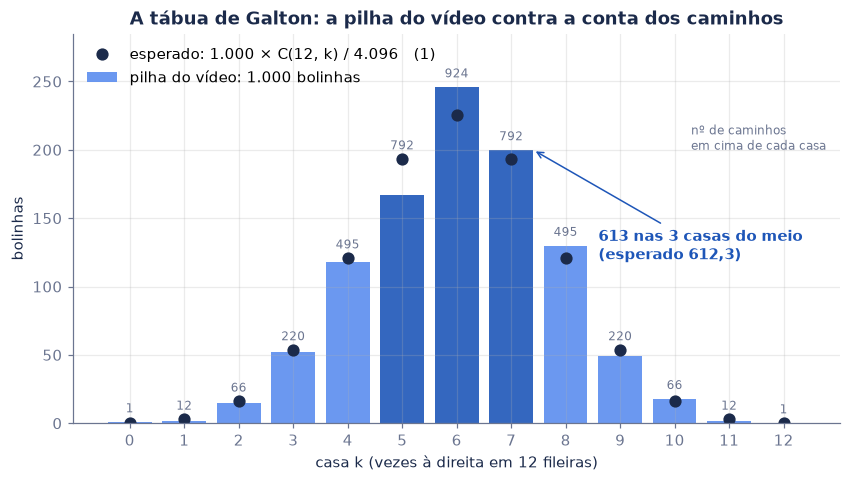

In [3]:
n = 12
k = np.arange(n + 1)
caminhos = np.array([math.comb(n, j) for j in k])
p_k = caminhos / 2 ** n                                          # (1)
esperado = 1000 * p_k
tab = pd.DataFrame({"casa k": k, "caminhos C(12, k)": caminhos, "probabilidade (1)": p_k, "esperado em 1.000": esperado, "pilha do vídeo": pilha})
display(tab.style.format({"probabilidade (1)": "{:.4f}", "esperado em 1.000": "{:.1f}"}, **fmt).hide(axis="index"))

meio = p_k[5:8].sum()
print(f"3 casas do meio: {mil(caminhos[5:8].sum())} de 4.096 caminhos = {pct(meio)} -> esperado {br(1000 * meio, 1)} bolinhas ± {br(math.sqrt(1000 * meio * (1 - meio)), 1)}; o vídeo teve 613")
# qui-quadrado com as caudas agrupadas (esperado >= 5 em cada grupo); p-valor por simulação
agrupa = lambda v: np.column_stack([v[..., :3].sum(-1), v[..., 3:10], v[..., 10:].sum(-1)])
O, E_ = agrupa(pilha[None, :])[0], agrupa(esperado[None, :])[0]
qui2 = ((O - E_) ** 2 / E_).sum()
sim = agrupa(np.random.default_rng(2026).multinomial(1000, p_k, size=20000))
p_qui2 = (((sim - E_) ** 2 / E_).sum(axis=1) >= qui2).mean()
print(f"qui-quadrado da pilha contra (1): {br(qui2)} em 9 grupos; p-valor (20.000 tábuas simuladas) = {br(p_qui2)}")
assert caminhos.tolist() == [1, 12, 66, 220, 495, 792, 924, 792, 495, 220, 66, 12, 1]          # os números em cima da pilha no vídeo
assert caminhos.sum() == 4096 and caminhos[5:8].sum() == 2508 and round(1000 * meio, 1) == 612.3

fig, ax = plt.subplots()
ax.bar(k, pilha, color=[BLUE if 5 <= j <= 7 else LIGHT for j in k], alpha=0.9, label="pilha do vídeo: 1.000 bolinhas")
ax.plot(k, esperado, "o", color=NAVY, ms=7, label="esperado: 1.000 × C(12, k) / 4.096   (1)")
for j in k:
    ax.text(j, max(pilha[j], esperado[j]) + 7, f"{caminhos[j]}", ha="center", color=GREY, fontsize=8)
ax.text(10.3, 200, "nº de caminhos\nem cima de cada casa", color=GREY, fontsize=8)
ax.annotate("613 nas 3 casas do meio\n(esperado 612,3)", (7.4, 200), (8.6, 120), color=BLUE, weight="bold", arrowprops=dict(arrowstyle="->", color=BLUE))
ax.set(title="A tábua de Galton: a pilha do vídeo contra a conta dos caminhos", xlabel="casa k (vezes à direita em 12 fileiras)", ylabel="bolinhas", xticks=k, ylim=(0, 285))
ax.legend(frameon=False, loc="upper left"); plt.show()

**Leitura.** A pilha do vídeo é a eq. (1) com ruído de amostra: as 3 casas do meio concentram 2.508 dos 4.096 caminhos (61,2 %), e caíram nelas 613 bolinhas para 612,3 esperadas. O teste de qui-quadrado não vê diferença entre a pilha e a binomial (p-valor de 0,54).

## 2. Do binômio ao sino (De Moivre–Laplace) e a raiz quadrada — eqs. (2) e (3)

Em 1733, Abraham de Moivre mostrou que, para $n$ grande, a binomial (1) com moeda honesta fica igual a uma curva só, com o meio em $n/2$ e a largura em $\sqrt{n}/2$:

$$
P(K = k) \approx \frac{1}{\sqrt{2\pi\,n/4}}\,\exp\!\left(-\frac{(k - n/2)^2}{2\,n/4}\right) \tag{2}
$$

A conta usa a fórmula de Stirling para os fatoriais (a nota técnica faz a demonstração). Laplace generalizou para moeda viciada. A curva da direita é a **densidade normal** com média $n/2$ e variância $n/4$.

O passeio aleatório é a mesma coisa vista de outro jeito: com passos $\varepsilon_i = \pm 1$, a posição depois de $n$ passos é $S_n = \sum_{i=1}^{n} \varepsilon_i = 2K - n$. Como os passos são independentes e cada um tem variância 1, as variâncias somam:

$$
\operatorname{Var}(S_n) = \sum_{i=1}^{n}\operatorname{Var}(\varepsilon_i) = n \qquad\Longrightarrow\qquad \operatorname{dp}(S_n) = \sqrt{n} \tag{3}
$$

É a regra do vídeo da raiz quadrada: $\sqrt{12} \approx 3{,}5$ na tábua e $\sqrt{400} = 20$ nos 1.000 passeios.

n,k,exato (1),De Moivre (2),erro relativo
12,6,"0,225586","0,230329","+2,1%"
12,4,"0,120850","0,118255","-2,1%"
12,2,"0,016113","0,016004","-0,7%"
12,0,"0,000244","0,000571","+133,9%"
400,200,"0,039869","0,039894","+0,1%"
400,180,"0,005405","0,005399","-0,1%"
400,160,"0,000013","0,000013","+3,5%"


Stirling: 12! = 479.001.600; √(2π·12)·(12/e)^12 = 475.687.486 (razão 1,0070; 1 + 1/(12·12) = 1,0069)
1.000 passeios, 400 passos: média −0,07, desvio-padrão 19,92 (teoria (3): 20; erro-padrão da estimativa ≈ 0,45)


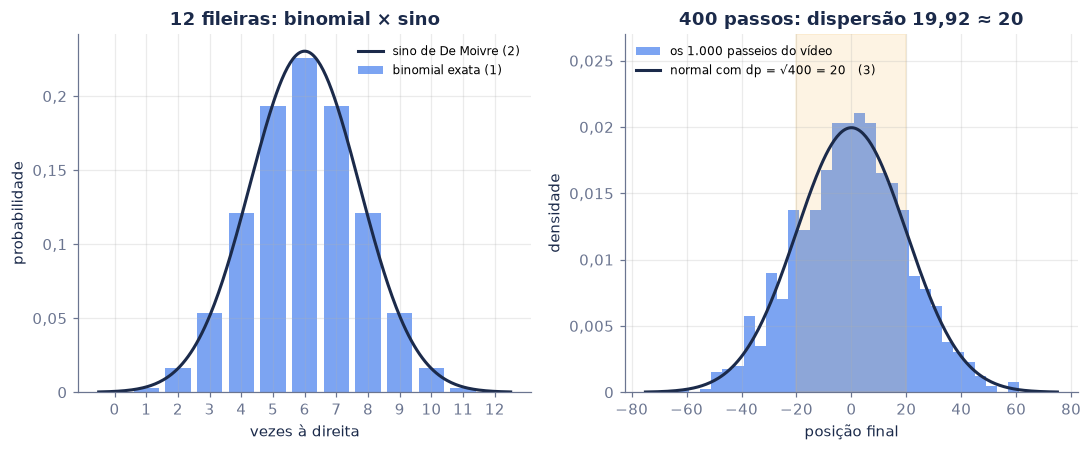

In [4]:
dml = lambda kk, nn: math.exp(-(kk - nn / 2) ** 2 / (nn / 2)) / math.sqrt(math.pi * nn / 2)     # (2)
linhas = []
for nn, kk in [(12, 6), (12, 4), (12, 2), (12, 0), (400, 200), (400, 180), (400, 160)]:
    exato = math.comb(nn, kk) / 2 ** nn
    linhas.append({"n": nn, "k": kk, "exato (1)": exato, "De Moivre (2)": dml(kk, nn), "erro relativo": dml(kk, nn) / exato - 1})
display(pd.DataFrame(linhas).style.format({"exato (1)": "{:.6f}", "De Moivre (2)": "{:.6f}", "erro relativo": "{:+.1%}"}, **fmt).hide(axis="index"))

stirling = lambda m: math.sqrt(2 * math.pi * m) * (m / math.e) ** m                   # a fórmula de Stirling
print(f"Stirling: 12! = {mil(math.factorial(12))}; √(2π·12)·(12/e)^12 = {mil(round(stirling(12)))} (razão {br(math.factorial(12) / stirling(12), 4)}; 1 + 1/(12·12) = {br(1 + 1 / 144, 4)})")
fim = passeios[:, -1]
ep_dp = 20 / math.sqrt(2 * len(fim))            # erro-padrão do desvio-padrão de 1.000 normais
print(f"1.000 passeios, 400 passos: média {br(fim.mean())}, desvio-padrão {br(dp400)} (teoria (3): 20; erro-padrão da estimativa ≈ {br(ep_dp)})")
assert abs(dp400 - 20) < 2 * ep_dp

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
xx = np.linspace(-0.5, 12.5, 300)
a1.bar(k, p_k, color=LIGHT, alpha=0.8, label="binomial exata (1)")
a1.plot(xx, [dml(v, 12) for v in xx], color=NAVY, lw=2, label="sino de De Moivre (2)")
a1.set(title="12 fileiras: binomial × sino", xlabel="vezes à direita", ylabel="probabilidade", xticks=k); a1.legend(frameon=False, fontsize=8)
a2.hist(fim, bins=np.arange(-71, 72, 4), density=True, color=LIGHT, alpha=0.8, label="os 1.000 passeios do vídeo")
ss = np.linspace(-75, 75, 300)
a2.plot(ss, phi(ss / 20) / 20, color=NAVY, lw=2, label="normal com dp = √400 = 20   (3)")
a2.axvspan(-20, 20, color=AMBER, alpha=0.15)
a2.set(title=f"400 passos: dispersão {br(dp400)} ≈ 20", xlabel="posição final", ylabel="densidade", ylim=(0, 0.027)); a2.legend(frameon=False, fontsize=8, loc="upper left")
for a in (a1, a2):
    a.yaxis.set_major_formatter(virgula)
plt.tight_layout(); plt.show()

**Leitura.** No meio, a aproximação (2) já é boa com 12 fileiras (2 % de erro na casa 6) e quase perfeita com 400 passos. Nas pontas, não: a casa 0 da tábua tem probabilidade exata de 1/4.096, e o sino dá 2,3 vezes isso. A binomial tem cauda **mais fina** que o sino, porque é limitada (não dá para ir à direita 13 vezes em 12 fileiras). Guarde a ideia: **o sino acerta o meio muito antes de acertar as caudas.** Com retornos de ação, o erro nas caudas vai para o outro lado.

## 3. O teorema central do limite: passos de qualquer forma — eq. (4)

Os passos nem precisam ser $\pm 1$. Se $X_1, X_2, \dots$ são independentes, com a mesma distribuição, média $\mu$ e variância $\sigma^2$ finita, então a soma padronizada converge para o sino:

$$
\frac{S_n - n\mu}{\sigma\sqrt{n}} \;\xrightarrow{\;d\;}\; N(0, 1), \qquad S_n = X_1 + \cdots + X_n \tag{4}
$$

É o **teorema central do limite** (TCL). No vídeo, cada salto é uniforme entre −1 e +1: média 0, variância $1/3$, uma distribuição chata, sem sino nenhum. A soma de 100 desses saltos tem desvio-padrão $\sqrt{100/3} = 5{,}77$ e já é um sino.

Quão rápido? A **curtose em excesso** (zero no sino) da uniforme é −1,2, e a de uma soma de $n$ passos independentes é a do passo dividida por $n$ (nota técnica). A **distância máxima** entre a acumulada da soma e $\Phi$ tem um teto que vale para qualquer passo: a desigualdade de Berry–Esseen, $\sup_x |F_n(x) - \Phi(x)| \le C\,\rho/(\sigma^3\sqrt{n})$, com $\rho = E|X|^3$ e $C < 0{,}48$.

passos somados,dp da soma,teoria √(n/3),curtose em excesso,"teoria −1,2/n",distância a Φ,teto de Berry–Esseen
1,"0,576","0,577","-1,195","-1,200","0,0568","0,617"
2,"0,816","0,816","-0,601","-0,600","0,0173","0,436"
6,"1,415","1,414","-0,198","-0,200","0,0063","0,252"
100,"5,778","5,774","+0,009","-0,012","0,0013","0,062"


somas.std() da tela = 5,778 (teoria 5,774); com 100.000 somas, o ruído de amostra é ~0,003 na distância a Φ e ~0,015 na curtose
Berry–Esseen para a uniforme: ρ/σ³ = E|X|³/σ³ = (1/4)/(1/3)^1,5 = 1,299; teto = 0,4748 × 1,299 / √n


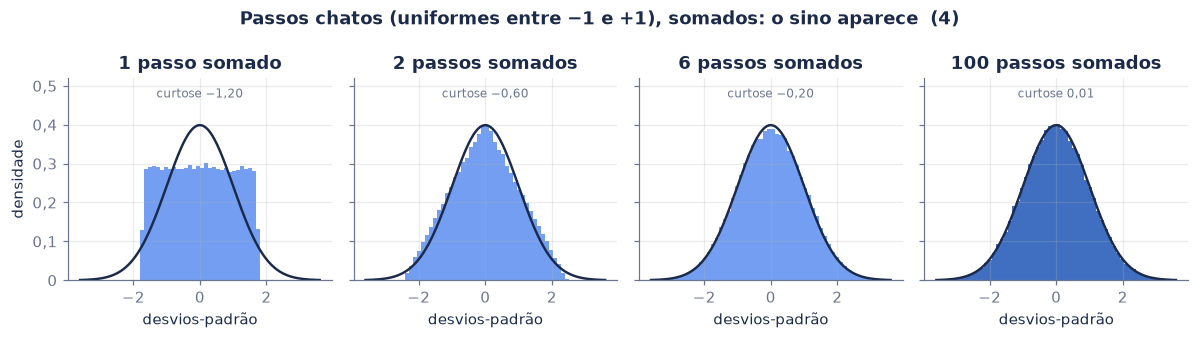

In [5]:
curt = lambda x: float(np.mean((x - x.mean()) ** 4) / x.var() ** 2 - 3)          # curtose em excesso (0 no sino)
assim = lambda x: float(np.mean((x - x.mean()) ** 3) / x.std() ** 3)
grade = np.sort(Phi_v(np.linspace(-6, 6, 4001)))
def dist_ks(x):                                      # maior distância entre a acumulada da amostra e Φ
    xs = np.sort((x - x.mean()) / x.std()); F = np.arange(1, len(xs) + 1) / len(xs)
    return float(np.max(np.abs(F - np.interp(xs, np.linspace(-6, 6, 4001), grade))))
rho_s3 = (1 / 4) / (1 / 3) ** 1.5                     # E|X|^3 / σ^3 da uniforme em (−1, 1)
linhas = []
for nn in (1, 2, 6, 100):
    s = saltos[:, :nn].sum(axis=1)
    linhas.append({"passos somados": nn, "dp da soma": s.std(), "teoria √(n/3)": math.sqrt(nn / 3), "curtose em excesso": curt(s),
                   "teoria −1,2/n": -1.2 / nn, "distância a Φ": dist_ks(s), "teto de Berry–Esseen": 0.4748 * rho_s3 / math.sqrt(nn)})
tcl = pd.DataFrame(linhas)
display(tcl.style.format({"dp da soma": "{:.3f}", "teoria √(n/3)": "{:.3f}", "curtose em excesso": "{:+.3f}", "teoria −1,2/n": "{:+.3f}", "distância a Φ": "{:.4f}", "teto de Berry–Esseen": "{:.3f}"}, **fmt).hide(axis="index"))
print(f"somas.std() da tela = {br(somas.std(), 3)} (teoria 5,774); com 100.000 somas, o ruído de amostra é ~0,003 na distância a Φ e ~{br(math.sqrt(24 / 100000), 3)} na curtose")
print(f"Berry–Esseen para a uniforme: ρ/σ³ = E|X|³/σ³ = (1/4)/(1/3)^1,5 = {br(rho_s3, 3)}; teto = 0,4748 × {br(rho_s3, 3)} / √n")
assert abs(somas.std() - math.sqrt(100 / 3)) < 0.03 and abs(tcl["curtose em excesso"].iloc[0] + 1.2) < 0.01

fig, axs = plt.subplots(1, 4, figsize=(11, 3.1), sharey=True)
bordas, xg = np.linspace(-3.6, 3.6, 61), np.linspace(-3.6, 3.6, 300)
for a, nn in zip(axs, (1, 2, 6, 100)):
    s = saltos[:, :nn].sum(axis=1); s = s / s.std()
    a.hist(s, bins=bordas, density=True, color=LIGHT if nn < 100 else BLUE, alpha=0.85)
    a.plot(xg, phi(xg), color=NAVY, lw=1.6)
    a.set(title=f"{nn} passo{'s' if nn > 1 else ''} somado{'s' if nn > 1 else ''}", xlabel="desvios-padrão", ylim=(0, 0.52))
    a.text(0, 0.47, f"curtose {br(curt(s), 2)}", ha="center", color=GREY, fontsize=8)
    a.yaxis.set_major_formatter(virgula); a.xaxis.set_major_formatter(virgula)
axs[0].set_ylabel("densidade"); fig.suptitle("Passos chatos (uniformes entre −1 e +1), somados: o sino aparece  (4)", color=NAVY, weight="bold")
plt.tight_layout(); plt.show()

O passo uniforme é simétrico, e por isso a convergência é rápida: o primeiro termo do erro (proporcional à assimetria, $1/\sqrt{n}$) é zero, e sobra um termo de ordem $1/n$. Com um passo **assimétrico**, o sino demora muito mais. Um passo de "loteria" que perde 1 com 90 % de chance e ganha 9 com 10 % também tem média zero, mas assimetria 2,67, e a soma de 100 deles ainda é torta. A conta abaixo é exata (o número de prêmios é binomial):

In [6]:
W = np.arange(101)
pW = np.array([math.comb(100, w) * 0.1 ** w * 0.9 ** (100 - w) for w in W])     # nº de prêmios em 100 passos
soma_lot, dp_lot = 10 * W - 100, math.sqrt(100 * 9)                                  # soma = 9W − (100 − W)
dir3, esq3 = pW[soma_lot > 3 * dp_lot].sum(), pW[soma_lot < -3 * dp_lot].sum()
print(f"soma de 100 passos de loteria: dp = {br(dp_lot, 0)}, assimetria = {br(2.6667 / 10, 3)}")
print(f"P(acima de +3 dp) = {br(100 * dir3, 3)} %  ·  P(abaixo de −3 dp) = {br(100 * esq3, 4)} %   (sino: {br(100 * (1 - Phi(3)), 3)} % de cada lado)")
assert round(100 * esq3, 4) == round(100 * 0.9 ** 100, 4)

soma de 100 passos de loteria: dp = 30, assimetria = 0,267
P(acima de +3 dp) = 0,198 %  ·  P(abaixo de −3 dp) = 0,0027 %   (sino: 0,135 % de cada lado)


**Leitura.** Com passos simétricos, 6 passos já desenham o sino e 100 passos ficam a 0,001 dele, abaixo do ruído de amostra. O teto de Berry–Esseen (0,06 com 100 passos) é uma garantia para o **pior** passo possível, não uma previsão. Com passos tortos, a soma de 100 ainda tem a cauda direita 50 % mais gorda que a do sino e a esquerda 50 vezes mais fina. Opções e crédito têm retornos assim: o sino da soma demora a chegar.

## 4. A regra 68–95–99,7, o "1 em 370" e a garantia de Chebyshev — eqs. (5) e (6)

O sino padrão tem densidade e probabilidades dentro de $\pm k$ desvios dadas por

$$
\varphi(z) = \frac{1}{\sqrt{2\pi}}\,e^{-z^2/2}, \qquad P(|Z| \le k) = 2\,\Phi(k) - 1 = \operatorname{erf}\!\left(\frac{k}{\sqrt{2}}\right) \tag{5}
$$

Daí saem 68,27 %, 95,45 % e 99,73 %, e o "1 em 370": $1/P(|Z| > 3) = 1/0{,}0027 = 370{,}4$.

E se você **não** souber que a distribuição é normal? A desigualdade de Chebyshev vale para qualquer distribuição com variância finita:

$$
P\big(|X - \mu| \ge k\sigma\big) \le \frac{1}{k^2} \tag{6}
$$

É uma garantia, não uma estimativa: pelo menos 75 % dentro de 2 desvios e 88,9 % dentro de 3, aconteça o que acontecer. A coluna da $t$ de Student com 3 graus de liberdade (seção 6) mostra uma distribuição de verdade entre as duas.

In [7]:
t3_alem = lambda kk: 1 - (2 / math.pi) * (kk / (1 + kk * kk) + math.atan(kk))      # P(|T|/√3 > k), t com 3 g.l. e variância 1
linhas = []
for kk in range(1, 7):
    pa = 2 * (1 - Phi(kk))
    linhas.append({"k": kk, "sino: dentro de ±k (5)": 1 - pa, "sino: além de k": pa, "1 em …": 1 / pa, "em dias úteis: 1 vez a cada … anos": 1 / pa / 252,
                   "t com 3 g.l.: além de k": t3_alem(kk), "Chebyshev (6): no máximo": min(1, 1 / kk ** 2)})
regra = pd.DataFrame(linhas)
display(regra.style.format({"sino: dentro de ±k (5)": "{:.4%}", "sino: além de k": "{:.2e}", "1 em …": "{:,.1f}", "em dias úteis: 1 vez a cada … anos": "{:,.2f}",
                            "t com 3 g.l.: além de k": "{:.2e}", "Chebyshev (6): no máximo": "{:.1%}"}, **fmt).hide(axis="index"))
assert [round(100 * v, 2) for v in regra["sino: dentro de ±k (5)"][:3]] == [68.27, 95.45, 99.73] and round(regra["1 em …"][2], 1) == 370.4

# cauda do sino de cabeça: a razão de Mills, 1 − Φ(k) ≈ φ(k)/k
mills = pd.DataFrame([{"k": kk, "1 − Φ(k) exato": 1 - Phi(kk), "φ(k)/k": float(phi(kk)) / kk, "φ(k)/k · (1 − 1/k²)": float(phi(kk)) / kk * (1 - 1 / kk ** 2)} for kk in (2, 3, 4, 5, 6)])
display(mills.style.format({c: "{:.3e}" for c in mills.columns[1:]}, **fmt).hide(axis="index"))

k,sino: dentro de ±k (5),sino: além de k,1 em …,em dias úteis: 1 vez a cada … anos,t com 3 g.l.: além de k,Chebyshev (6): no máximo
1,"68,2689%","3,17e-01","3,2","0,01","1,82e-01","100,0%"
2,"95,4500%","4,55e-02","22,0","0,09","4,05e-02","25,0%"
3,"99,7300%","2,70e-03","370,4","1,47","1,38e-02","11,1%"
4,"99,9937%","6,33e-05","15.787,2","62,65","6,17e-03","6,2%"
5,"99,9999%","5,73e-07","1.744.277,9","6.921,74","3,24e-03","4,0%"
6,"100,0000%","1,97e-09","506.797.317,4","2.011.100,47","1,90e-03","2,8%"


k,1 − Φ(k) exato,φ(k)/k,φ(k)/k · (1 − 1/k²)
2,"2,275e-02","2,700e-02","2,025e-02"
3,"1,350e-03","1,477e-03","1,313e-03"
4,"3,167e-05","3,346e-05","3,137e-05"
5,"2,867e-07","2,973e-07","2,855e-07"
6,"9,866e-10","1,013e-09","9,845e-10"


A simulação da tela deu 1 em **361** (277 somas em 100.000). Duas coisas explicam a diferença para 370. Primeiro, a soma de 100 uniformes não é exatamente normal: a cauda dela é um pouco **mais fina** (curtose −0,012). A probabilidade exata sai da distribuição de Irwin–Hall, uma soma alternada que precisa de muitas casas decimais, e a nota técnica mostra que a correção de Edgeworth dá o mesmo número. Segundo, ruído de amostra: o desvio-padrão de uma contagem de ~262 é ~16.

In [8]:
getcontext().prec = 250
def irwin_hall_cdf(x, nn=100):                       # P(soma de nn uniformes em (0, 1) <= x), exata
    x = Decimal(x)
    return sum((-1) ** j * math.comb(nn, j) * (x - j) ** nn for j in range(int(x) + 1)) / math.factorial(nn)
p_exato = float(2 * irwin_hall_cdf(Decimal(50) - 3 * Decimal(100 / 12).sqrt()))
kappa4 = -1.2 / 100
p_edge = p3 + 2 * float(phi(3)) * kappa4 / 24 * (3 ** 3 - 3 * 3)                      # Edgeworth com o termo de curtose
print(f"além de 3 dp: sino 1 em {br(1 / p3, 1)} · soma de 100 uniformes, exato 1 em {br(1 / p_exato, 1)} · Edgeworth 1 em {br(1 / p_edge, 1)} · simulação 1 em {br(um_em, 1)}")
esp = 100_000 * p_exato
print(f"esperado em 100.000 somas: {br(esp, 1)} ± {br(math.sqrt(esp), 1)}; a simulação teve 277 ({br((277 - esp) / math.sqrt(esp), 2)} desvios acima)")
assert round(1 / p_exato) == 382 and abs(1 / p_edge - 1 / p_exato) < 0.5

além de 3 dp: sino 1 em 370,4 · soma de 100 uniformes, exato 1 em 381,7 · Edgeworth 1 em 381,7 · simulação 1 em 361,0
esperado em 100.000 somas: 262,0 ± 16,2; a simulação teve 277 (0,93 desvios acima)


## 5. Uma ação a 1 % ao dia: a raiz do tempo e a grade da moeda — eq. (7)

Um ano é a soma de 252 movimentos diários. Se os dias são independentes e cada um oscila $\sigma_1$, a eq. (3) dá a oscilação em $T$ dias:

$$
\sigma_T = \sigma_1\,\sqrt{T} \qquad\Longrightarrow\qquad \sigma_{\text{anual}} = 1\,\% \times \sqrt{252} = 15{,}9\,\% \tag{7}
$$

Pelo sino, o ano termina dentro de ±16 % em cerca de 2 anos a cada 3, dentro de ±32 % em 19 a cada 20, e passa de ±48 % uma vez a cada 370 anos. O vídeo simula 20.000 anos de dias de exatamente +1 % ou −1 %:

In [9]:
rng_y = np.random.default_rng(3)
dias = 0.01 * rng_y.choice(moeda, (20000, 252))
ano = dias.sum(1)
d16, d32 = int((abs(ano) <= anual).sum()), int((abs(ano) <= 2 * anual).sum())
print(f"dentro de ±{pct(anual)}: {mil(d16)} de 20.000 anos = {pct(d16 / 20000)}  ·  dentro de ±{pct(2 * anual)}: {mil(d32)} = {pct(d32 / 20000)}")
assert (d16, d32) == (13236, 19023) and round(100 * d16 / 20000, 1) == 66.2 and round(100 * d32 / 20000, 1) == 95.1
assert round(d16 / 20000 * 3) == 2 and round(d32 / 20000 * 20) == 19      # "2 em 3" e "19 em 20"

# a grade da moeda: com ±1 % por dia, o ano é um número PAR de %, entre −252 e +252
P_K = lambda a, b: sum(math.comb(252, j) for j in range(a, b + 1)) / 2 ** 252
dentro16, dentro32 = P_K(119, 133), P_K(111, 141)          # |S| <= 14 e |S| <= 30
alem48 = 1 - P_K(103, 149)                                  # |S| >= 48
print(f"binomial exata: dentro de ±15,9 % = {pct(dentro16, 2)}  ·  dentro de ±31,7 % = {pct(dentro32, 2)}  ·  além de 47,6 %: 1 em {br(1 / alem48, 0)} anos")
print(f"sino:            dentro de ±1 dp = 68,27 %  ·  ±2 dp = 95,45 %  ·  além de 3 dp: 1 em 370 anos")
print(f"sino com correção de continuidade (|S| <= 15): {pct(2 * Phi(15 / math.sqrt(252)) - 1, 2)}")
mediana = (1.01 * 0.99) ** 126 - 1                           # 126 dias de alta e 126 de baixa, compostos
print(f"compondo em vez de somar: o ano mediano (126 altas e 126 baixas) rende {pct(mediana, 2)}; −σ²/2 = {pct(-anual ** 2 / 2, 2)}")

dentro de ±15,9 %: 13.236 de 20.000 anos = 66,2 %  ·  dentro de ±31,7 %: 19.023 = 95,1 %
binomial exata: dentro de ±15,9 % = 65,53 %  ·  dentro de ±31,7 % = 94,94 %  ·  além de 47,6 %: 1 em 334 anos
sino:            dentro de ±1 dp = 68,27 %  ·  ±2 dp = 95,45 %  ·  além de 3 dp: 1 em 370 anos
sino com correção de continuidade (|S| <= 15): 65,53 %
compondo em vez de somar: o ano mediano (126 altas e 126 baixas) rende −1,25 %; −σ²/2 = −1,26 %


**Leitura.** A simulação deu 66,2 % e não 68,3 % por um motivo bonito: com passos de exatamente ±1 %, o ano só pode terminar em número par de por cento. "Dentro de ±15,9 %" quer dizer "dentro de ±14 %", porque ±16 % já fica fora. A binomial exata dá 65,5 %, e o sino com a correção de continuidade (cortar em 15, no meio do caminho entre 14 e 16) dá o mesmo número. Ações de verdade não andam em grade, então o 68 % é a referência certa para elas. A regra do vídeo continua valendo: **2 anos em 3** e **19 em 20**.

Detalhe que fica para a nota técnica: retornos de verdade se compõem, não se somam. Com 1 % ao dia, a mediana do ano fica $-\sigma^2/2 \approx -1{,}3\,\%$ abaixo da média (o assunto do vídeo dos retornos).

## 6. Caudas gordas simuladas: a $t$ de Student — eq. (8)

No fim do vídeo, dois mercados simulados com a **mesma oscilação média**: um com dias normais e outro com dias de uma $t$ de Student com $\nu = 3$ graus de liberdade, reescalada para ter desvio-padrão 1. A $t$ tem densidade

$$
\begin{gathered}
f_\nu(x) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\sqrt{\nu\pi}\;\Gamma\!\left(\frac{\nu}{2}\right)}\left(1 + \frac{x^2}{\nu}\right)^{-\frac{\nu+1}{2}} \\
\operatorname{Var} = \frac{\nu}{\nu-2}\ (\nu > 2), \qquad \text{curtose em excesso} = \frac{6}{\nu-4}\ (\nu > 4)
\end{gathered} \tag{8}
$$

A cauda cai como uma potência, $x^{-(\nu+1)}$, e não como $e^{-x^2/2}$. Com $\nu = 3$, a variância existe (3), mas **a curtose é infinita**: o quarto momento não existe.

40 anos (10.080 dias) além de 4 desvios: sino 0 (esperado 0,64), caudas gordas 78
t com 3 g.l. e desvio-padrão verdadeiro (√3): esperado 62,1 dias; o desvio de amostra dessa série foi 1,737 (√3 = 1,732)


em 2.000 sementes: mediana 65 dias, 90 % entre 49 e 77; P(>= 78) = 4,5 %
o desvio-padrão de amostra da t com 3 g.l. varia de 1,62 a 1,90 (90 % das sementes, √3 = 1,73): de −6,4 % a +9,8 %; numa normal com 10.080 dias, ±1,2 %


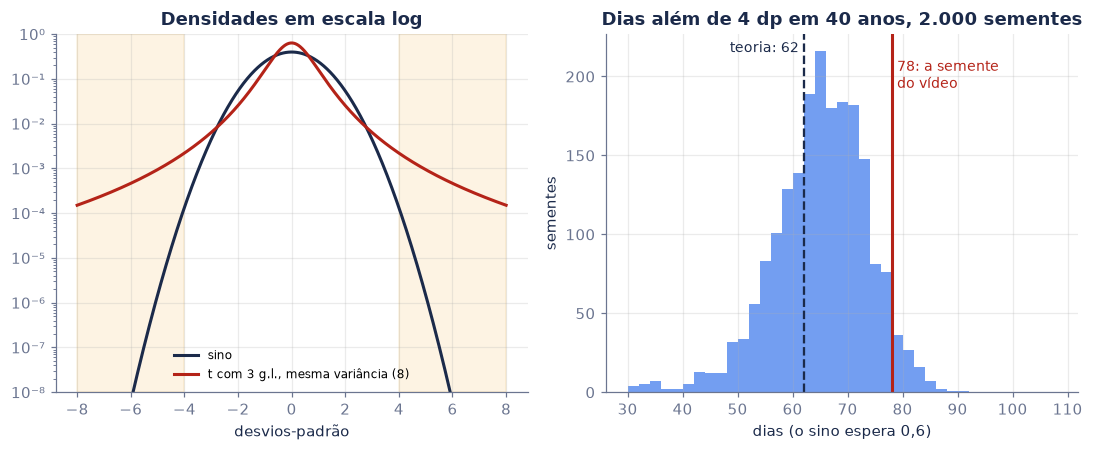

In [10]:
rng_m = np.random.default_rng(11)
normal = rng_m.standard_normal(504)
t3 = rng_m.standard_t(3, 504); t3 = t3 / t3.std()
n40 = rng_m.standard_normal(10080); f40_bruto = rng_m.standard_t(3, 10080); f40 = f40_bruto / f40_bruto.std()
alem4 = [int((abs(n40) > 4).sum()), int((abs(f40) > 4).sum())]
esperado_sino = 10080 * 2 * (1 - Phi(4))
teoria_t3 = 10080 * t3_alem(4)
print(f"40 anos (10.080 dias) além de 4 desvios: sino {alem4[0]} (esperado {br(esperado_sino, 2)}), caudas gordas {alem4[1]}")
print(f"t com 3 g.l. e desvio-padrão verdadeiro (√3): esperado {br(teoria_t3, 1)} dias; o desvio de amostra dessa série foi {br(f40_bruto.std(), 3)} (√3 = 1,732)")
assert alem4 == [0, 78] and round(esperado_sino, 1) == 0.6

# 2.000 sementes: o "78" é típico?
cont, dps = [], []
for s in range(2000):
    f = np.random.default_rng(s).standard_t(3, 10080)
    cont.append(int((abs(f / f.std()) > 4).sum())); dps.append(f.std())
cont, dps = np.array(cont), np.array(dps)
print(f"em 2.000 sementes: mediana {np.median(cont):.0f} dias, 90 % entre {np.percentile(cont, 5):.0f} e {np.percentile(cont, 95):.0f}; P(>= 78) = {pct((cont >= 78).mean())}")
print(f"o desvio-padrão de amostra da t com 3 g.l. varia de {br(np.percentile(dps, 5), 2)} a {br(np.percentile(dps, 95), 2)} (90 % das sementes, √3 = 1,73): "
      f"de {pct(np.percentile(dps, 5) / math.sqrt(3) - 1)} a +{pct(np.percentile(dps, 95) / math.sqrt(3) - 1)}; numa normal com 10.080 dias, ±{pct(1.645 / math.sqrt(2 * 10080))}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
xg = np.linspace(-8, 8, 801)
ft3 = lambda x: math.sqrt(3) * 2 / (math.pi * math.sqrt(3)) / (1 + (math.sqrt(3) * x) ** 2 / 3) ** 2   # densidade de T/√3 (ν = 3)
a1.semilogy(xg, phi(xg), color=NAVY, lw=2, label="sino")
a1.semilogy(xg, [ft3(v) for v in xg], color=RED, lw=2, label="t com 3 g.l., mesma variância (8)")
a1.axvspan(4, 8, color=AMBER, alpha=0.15); a1.axvspan(-8, -4, color=AMBER, alpha=0.15)
a1.set(title="Densidades em escala log", xlabel="desvios-padrão", ylim=(1e-8, 1), xticks=range(-8, 9, 2)); a1.legend(frameon=False, fontsize=8, loc="lower center")
eixo_log_y(a1); a1.xaxis.set_major_formatter(virgula)
a2.hist(cont, bins=np.arange(30, 110, 2), color=LIGHT, alpha=0.85)
a2.axvline(78, color=RED, lw=2); a2.text(79, a2.get_ylim()[1] * 0.85, "78: a semente\ndo vídeo", color=RED, fontsize=9)
a2.axvline(teoria_t3, color=NAVY, ls="--"); a2.text(teoria_t3 - 1, a2.get_ylim()[1] * 0.95, f"teoria: {br(teoria_t3, 0)}", color=NAVY, fontsize=9, ha="right")
a2.set(title="Dias além de 4 dp em 40 anos, 2.000 sementes", xlabel="dias (o sino espera 0,6)", ylabel="sementes")
plt.tight_layout(); plt.show()

**Leitura.** Com a mesma oscilação média, o sino espera 0,6 dia além de 4 desvios em 40 anos; a $t$ com 3 graus de liberdade, uns 62. A semente do vídeo deu 78, no alto do que é normal para essa distribuição (4,5 % das sementes dão 78 ou mais). Não foi erro de escala: o desvio de amostra dessa série (1,737) bate com o verdadeiro (√3 = 1,732); foi sorte na contagem. Mas a escala da $t$ com $\nu = 3$ é instável de verdade: entre sementes, o desvio de amostra erra de −6 % a +10 %, contra ±1 % numa normal com o mesmo número de dias. Sem quarto momento, **medir caudas em "desvios-padrão" fica instável justamente quando as caudas são gordas.**

## 7. 🇧🇷 Ibovespa desde 1995 contra o sino: a tabela de Fama (1965)

Agora o dado real. Retorno diário do Ibovespa, em log, de 02/01/1995 (depois da hiperinflação e da troca de moeda) a 16/10/2026. Duas limpezas: não há datas repetidas, e 13 dias têm retorno exatamente zero, todos feriados em que o Yahoo repetiu o fechamento anterior (15/11/1995, 29/12/2017…). Esses saem. Os maiores saltos são reais: 15/01/1999 (+33 %) é o dia em que o real passou a flutuar.

Mandelbrot (1963) olhou preços de algodão e disse que o sino não servia: as caudas eram gordas demais. Fama (1965) testou a ideia nas 30 ações do Dow Jones, montando uma tabela simples: **que fração dos dias cai dentro de 0,5, 1, 1,5, 2, 3… desvios-padrão**, contra o que o sino prevê. Ele achou dias demais perto do meio, de menos nos "ombros" e demais nas caudas. A mesma tabela com o Ibovespa:

In [11]:
ib = pd.read_csv("dados/ibovespa.csv", parse_dates=["data"]).set_index("data")["ibov"]
assert not ib.index.duplicated().any()
r_bruto = np.log(ib).diff().dropna()
r_bruto = r_bruto[r_bruto.index >= "1995-01-01"]
zeros = r_bruto[r_bruto == 0]
r = r_bruto[r_bruto != 0]
N = len(r)
print(f"{mil(len(r_bruto))} retornos; {len(zeros)} dias com retorno zero (feriados repetidos) saem -> {mil(N)} dias, de {r.index[0]:%d/%m/%Y} a {r.index[-1]:%d/%m/%Y} ({br(N / 252, 1)} anos de pregão)")
print("dias com retorno zero:", ", ".join(f"{d:%d/%m/%Y}" for d in zeros.index))
mu_d, sd_d = float(r.mean()), float(r.std())
zi = (r - mu_d) / sd_d                                   # retorno em desvios-padrão da amostra inteira

def mbb(x, estat, L=63, B=1000, semente=7):              # bootstrap em blocos móveis (Künsch, 1989)
    x = np.asarray(x); nx = len(x); g = np.random.default_rng(semente)
    ini = g.integers(0, nx - L + 1, size=(B, -(-nx // L)))
    idx = (ini[:, :, None] + np.arange(L)).reshape(B, -1)[:, :nx]
    return np.array([estat(x[i]) for i in idx])
ic = lambda a: np.percentile(a, [2.5, 97.5])
b_sd, b_as, b_cu = mbb(r, np.std), mbb(r, assim), mbb(r, curt)
b_a4 = mbb(r, lambda x: int((np.abs(x - x.mean()) / x.std() > 4).sum()))
mom = pd.DataFrame({
    "estatística": ["desvio-padrão diário", "desvio-padrão anual, eq. (7)", "assimetria", "curtose em excesso", "dias além de 4 dp"],
    "Ibovespa": [br(100 * sd_d, 2) + " %", br(100 * sd_d * math.sqrt(252), 1) + " %", br(assim(r.values), 2), br(curt(r.values), 1), str(int((zi.abs() > 4).sum()))],
    "IC 95 % (bootstrap em blocos de 63 dias)": [f"{br(100 * ic(b_sd)[0], 2)} a {br(100 * ic(b_sd)[1], 2)} %", f"{br(100 * ic(b_sd)[0] * math.sqrt(252), 1)} a {br(100 * ic(b_sd)[1] * math.sqrt(252), 1)} %",
                                                 f"{br(ic(b_as)[0], 2)} a {br(ic(b_as)[1], 2)}", f"{br(ic(b_cu)[0], 1)} a {br(ic(b_cu)[1], 1)}", f"{ic(b_a4)[0]:.0f} a {ic(b_a4)[1]:.0f}"],
    "sino": ["—", "—", "0", "0", br(N * 2 * (1 - Phi(4)), 1)],
})
display(mom.style.hide(axis="index"))

7.875 retornos; 13 dias com retorno zero (feriados repetidos) saem -> 7.862 dias, de 02/01/1995 a 16/10/2026 (31,2 anos de pregão)
dias com retorno zero: 28/06/1995, 15/11/1995, 27/06/1996, 07/01/1997, 07/02/1997, 17/03/1997, 23/02/1998, 03/03/1998, 29/10/1999, 19/11/2002, 12/08/2004, 29/09/2010, 29/12/2017


estatística,Ibovespa,IC 95 % (bootstrap em blocos de 63 dias),sino
desvio-padrão diário,"1,96 %","1,71 a 2,18 %",—
"desvio-padrão anual, eq. (7)","31,1 %","27,1 a 34,6 %",—
assimetria,"0,28","−0,59 a 1,12",0
curtose em excesso,"15,4","5,8 a 25,2",0
dias além de 4 dp,53,30 a 67,"0,5"


In [12]:
ks = [0.5, 1, 1.5, 2, 3, 4, 5, 6]
fama = pd.DataFrame({
    "k desvios": ks,
    "Ibovespa: dentro de ±k": [float((zi.abs() <= kk).mean()) for kk in ks],
    "sino: dentro de ±k": [2 * Phi(kk) - 1 for kk in ks],
    "Ibovespa: dias além de k": [int((zi.abs() > kk).sum()) for kk in ks],
    "sino: dias além (esperado)": [N * 2 * (1 - Phi(kk)) for kk in ks],
})
fama["razão"] = fama["Ibovespa: dias além de k"] / fama["sino: dias além (esperado)"]
pequeno = lambda v: br(v, 1) if v >= 0.05 else f"{v:.1e}".replace(".", ",")
display(fama.style.format({"k desvios": lambda v: br(v, 1), "Ibovespa: dentro de ±k": lambda v: pct(v, 2), "sino: dentro de ±k": lambda v: pct(v, 2),
                           "Ibovespa: dias além de k": mil, "sino: dias além (esperado)": pequeno, "razão": lambda v: br(v, 1) if v < 1000 else mil(v)}).hide(axis="index")
        .set_caption(f"Ibovespa, {mil(N)} dias, desvio de {br(100 * sd_d, 2)} % da amostra inteira"))
assert N == 7862 and fama["Ibovespa: dias além de k"].tolist()[4:] == [113, 53, 27, 14]      # os números do texto abaixo

k desvios,Ibovespa: dentro de ±k,sino: dentro de ±k,Ibovespa: dias além de k,sino: dias além (esperado),razão
"0,5","50,51 %","38,29 %",3.891,"4.851,4","0,8"
"1,0","78,85 %","68,27 %",1.663,"2.494,7","0,7"
"1,5","90,77 %","86,64 %",726,"1.050,5","0,7"
"2,0","95,74 %","95,45 %",335,"357,7","0,9"
"3,0","98,56 %","99,73 %",113,"21,2","5,3"
"4,0","99,33 %","99,99 %",53,"0,5","106,4"
"5,0","99,66 %","100,00 %",27,"4,5e-03",5.990
"6,0","99,82 %","100,00 %",14,"1,6e-05",902.462


,retorno,em dp da amostra,em dp do dia anterior (9),evento
15/01/1999,"+33,4 %","+14,7","+5,9",Banco Central deixa o real flutuar
10/03/1995,"+25,6 %","+11,6",—,crise do México (1995)
10/09/1998,"−15,8 %","−8,8","−4,0",crise da Rússia (1998)
15/09/1998,"+18,7 %","+8,7","+2,6",
27/10/1997,"−15,0 %","−8,3","−5,7",crise asiática (1997)
12/03/2020,"−14,8 %","−8,2","−3,5",covid-19 (circuit breaker)
16/03/2020,"−13,9 %","−7,7","−2,3",covid-19 (circuit breaker)
13/10/2008,"+14,7 %","+6,9","+3,0",crise de 2008
18/05/2017,"−8,8 %","−4,7","−8,1",Joesley Day (circuit breaker)
26/02/2020,"−7,0 %","−3,7","−6,1",covid-19 chega ao Brasil (Cinzas)


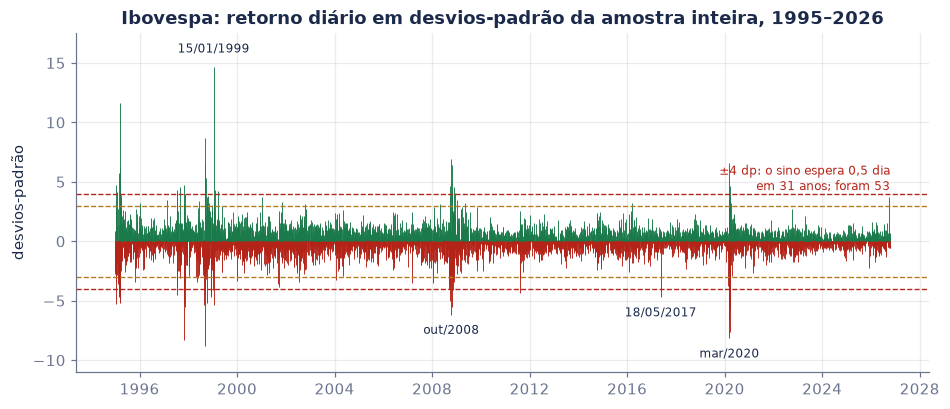

In [13]:
lam = 0.94                                               # EWMA do RiskMetrics (seção 8)
xv = r.to_numpy(); var_e = np.empty(N); var_e[0] = xv[:21].var()
for t in range(1, N):
    var_e[t] = lam * var_e[t - 1] + (1 - lam) * xv[t - 1] ** 2      # (9): só usa o passado
sig_e = pd.Series(np.sqrt(var_e), index=r.index)
ze = (r / sig_e).iloc[250:]                              # em desvios do dia anterior (1 ano de aquecimento)

eventos = {"1999-01-15": "Banco Central deixa o real flutuar", "1995-03-10": "crise do México (1995)", "1998-09-10": "crise da Rússia (1998)",
           "1997-10-27": "crise asiática (1997)", "2020-03-12": "covid-19 (circuit breaker)", "2020-03-16": "covid-19 (circuit breaker)",
           "2008-10-15": "crise de 2008", "2008-10-13": "crise de 2008", "2017-05-18": "Joesley Day (circuit breaker)",
           "2020-02-26": "covid-19 chega ao Brasil (Cinzas)", "2007-02-27": "queda da bolsa de Xangai", "2026-10-05": "segunda após o 1º turno de 2026"}
top = pd.DataFrame({"retorno": np.expm1(r), "em dp da amostra": zi, "em dp do dia anterior (9)": ze}).reindex(r.index)
sel = list(zi.abs().sort_values(ascending=False).index[:8]) + [pd.Timestamp(d) for d in ("2017-05-18", "2020-02-26", "2026-10-05")]
maiores = top.loc[sel].assign(evento=[eventos.get(f"{d:%Y-%m-%d}", "") for d in sel])
maiores.index = [f"{d:%d/%m/%Y}" for d in maiores.index]
sinal = lambda v, f: ("+" if v > 0 else "") + f(v)
display(maiores.style.format({"retorno": lambda v: sinal(v, pct), "em dp da amostra": lambda v: sinal(v, lambda u: br(u, 1)),
                              "em dp do dia anterior (9)": lambda v: "—" if pd.isna(v) else sinal(v, lambda u: br(u, 1))}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.vlines(zi.index, 0, zi.values, color=np.where(zi.values > 0, GREEN, RED), lw=0.6)
for s_ in (3, 4, -3, -4):
    ax.axhline(s_, color=GOLD if abs(s_) == 3 else RED, ls="--", lw=0.9)
ax.text(zi.index[-1], 4.3, " ±4 dp: o sino espera 0,5 dia\n em 31 anos; foram " + str(int((zi.abs() > 4).sum())), color=RED, fontsize=8, ha="right")
for d, txt in [("1999-01-15", "15/01/1999"), ("2008-10-15", "out/2008"), ("2020-03-12", "mar/2020"), ("2017-05-18", "18/05/2017")]:
    d = pd.Timestamp(d); v = float(zi.loc[d])
    ax.annotate(txt, (d, v), (d, v + (1.2 if v > 0 else -1.6)), ha="center", color=NAVY, fontsize=8)
ax.set(title="Ibovespa: retorno diário em desvios-padrão da amostra inteira, 1995–2026", ylabel="desvios-padrão", ylim=(-11, 17.5)); plt.show()

**Leitura.** É o padrão de Fama, só que mais forte. Há dias demais perto do meio (50,5 % dentro de meio desvio, contra 38,3 % no sino), de menos nos "ombros" (16,9 % dos dias entre 1 e 2 desvios, contra 27,2 %) e um excesso enorme nas caudas: 113 dias além de 3 desvios, onde o sino espera 21; 53 além de 4, onde ele espera meio dia; 14 além de 6, um evento que o sino coloca na casa de 1 em 500 milhões de dias. A curtose em excesso de 15,4 tem um intervalo de confiança enorme (de 5,8 a 25,2), e isso já é um sintoma: ela é dominada por meia dúzia de dias.

## 8. Quanto da cauda é volatilidade que muda: o desvio móvel — eq. (9)

Os dias extremos não estão espalhados: aparecem em blocos, em 1997–1999, 2008 e 2020. Medir tudo com um desvio único, o da amostra inteira, mistura anos calmos e anos de crise. Uma parte da "cauda gorda" pode ser só isso. O teste: medir cada dia em desvios **do momento**, estimados só com o passado. A média móvel exponencial do RiskMetrics (J.P. Morgan, 1996) faz isso com um parâmetro:

$$
\sigma_t^2 = \lambda\,\sigma_{t-1}^2 + (1-\lambda)\,r_{t-1}^2, \qquad \lambda = 0{,}94 \tag{9}
$$

O retorno padronizado é $r_t/\sigma_t$. Se a volatilidade que muda explicasse tudo, ele seria um sino.

medida,dp da amostra inteira,dp do dia anterior (9),sino (mesmo nº de dias)
curtose em excesso,"15,4","2,0",0
dias além de 3 dp,113,59,"20,6"
dias além de 4 dp,53,15,"0,5"
dias além de 5 dp,27,9,"4,4e-03"
dias além de 6 dp,14,2,"1,5e-05"


desvio-padrão de r/σ_t = 1,045 (o EWMA subestima um pouco); curtose padronizada: 2,04, IC 95 % 1,09 a 2,86
E[σ⁴]/E[σ²]² do EWMA, 1996–2026 = 3,53: só a vol que muda, com dias normais, daria curtose em excesso 7,59
vol que muda × cauda do dia padronizado: 5,04 × 3,53 − 3 = 14,78; curtose medida no mesmo período: 15,05


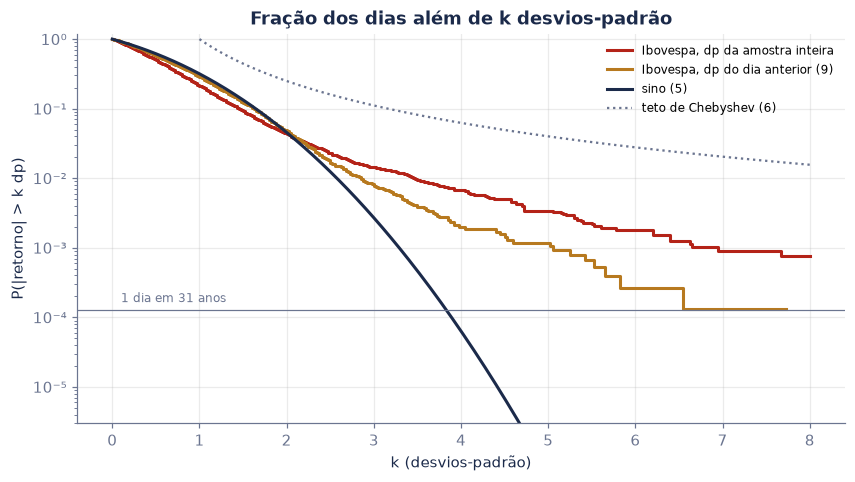

In [14]:
ze_u = ze / ze.std()                                       # mesma escala do sino (dp 1)
b_cu_e = mbb(ze_u, curt)
comp = pd.DataFrame({
    "medida": ["curtose em excesso", "dias além de 3 dp", "dias além de 4 dp", "dias além de 5 dp", "dias além de 6 dp"],
    "dp da amostra inteira": [br(curt(zi.values), 1)] + [str(int((zi.abs() > kk).sum())) for kk in (3, 4, 5, 6)],
    "dp do dia anterior (9)": [br(curt(ze_u.values), 1)] + [str(int((ze_u.abs() > kk).sum())) for kk in (3, 4, 5, 6)],
    "sino (mesmo nº de dias)": ["0"] + [pequeno(len(ze_u) * 2 * (1 - Phi(kk))) for kk in (3, 4, 5, 6)],
})
display(comp.style.hide(axis="index"))
print(f"desvio-padrão de r/σ_t = {br(float(ze.std()), 3)} (o EWMA subestima um pouco); curtose padronizada: {br(curt(ze_u.values), 2)}, IC 95 % {br(ic(b_cu_e)[0], 2)} a {br(ic(b_cu_e)[1], 2)}")
# decomposição: r = σ_t · z_t, com σ_t e z_t independentes -> E[r⁴]/E[r²]² = (E[σ⁴]/E[σ²]²) × E[z⁴]
s2 = sig_e.iloc[250:].to_numpy() ** 2
fator = float(np.mean(s2 ** 2) / np.mean(s2) ** 2)
print(f"E[σ⁴]/E[σ²]² do EWMA, 1996–2026 = {br(fator, 2)}: só a vol que muda, com dias normais, daria curtose em excesso {br(3 * fator - 3, 2)}")
print(f"vol que muda × cauda do dia padronizado: {br(curt(ze_u.values) + 3, 2)} × {br(fator, 2)} − 3 = {br((curt(ze_u.values) + 3) * fator - 3, 2)}; "
      f"curtose medida no mesmo período: {br(curt(r.iloc[250:].values), 2)}")

fig, ax = plt.subplots()
kg = np.linspace(0, 8, 321)
emp = lambda x: [(np.abs(x) > kk).mean() or np.nan for kk in kg]      # zero vira lacuna na escala log
ax.semilogy(kg, emp(zi.values), color=RED, lw=2, drawstyle="steps-post", label="Ibovespa, dp da amostra inteira")
ax.semilogy(kg, emp(ze_u.values), color=GOLD, lw=2, drawstyle="steps-post", label="Ibovespa, dp do dia anterior (9)")
ax.semilogy(kg, 2 * (1 - Phi_v(kg)), color=NAVY, lw=2, label="sino (5)")
ax.semilogy(kg[kg >= 1], 1 / kg[kg >= 1] ** 2, color=GREY, ls=":", lw=1.5, label="teto de Chebyshev (6)")
ax.axhline(1 / N, color=GREY, lw=0.8); ax.text(0.1, 1.3 / N, "1 dia em 31 anos", color=GREY, fontsize=8)
ax.set(title="Fração dos dias além de k desvios-padrão", xlabel="k (desvios-padrão)", ylabel="P(|retorno| > k dp)", ylim=(3e-6, 1.2)); ax.legend(frameon=False, fontsize=8)
eixo_log_y(ax); plt.show()

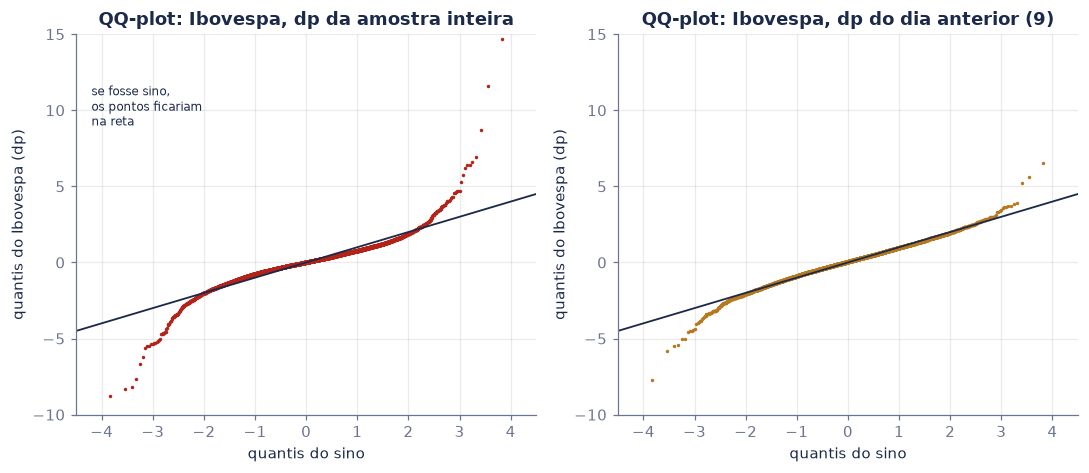

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4))
for a, x, cor, tit in [(a1, zi.values, RED, "dp da amostra inteira"), (a2, ze_u.values, GOLD, "dp do dia anterior (9)")]:
    xs = np.sort(x); teo = Phi_inv((np.arange(1, len(xs) + 1) - 0.5) / len(xs))
    a.plot(teo, xs, ".", color=cor, ms=2.5); a.plot([-4.5, 4.5], [-4.5, 4.5], color=NAVY, lw=1.2)
    a.set(title=f"QQ-plot: Ibovespa, {tit}", xlabel="quantis do sino", ylabel="quantis do Ibovespa (dp)", xlim=(-4.5, 4.5), ylim=(-10, 15))
a1.text(-4.2, 9, "se fosse sino,\nos pontos ficariam\nna reta", color=NAVY, fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** Medir cada dia contra a volatilidade do momento tira a maior parte do excesso: a curtose cai de 15,4 para 2,0 e os dias além de 4 desvios caem de 53 para 15 (com um ano a menos de amostra, por causa do aquecimento). **Boa parte da cauda gorda é volatilidade que muda** (Engle, 1982, ganhou o Nobel por modelar isso). Mas não tudo: o sino ainda esperaria meio dia além de 4 desvios, e não 15; o QQ-plot da direita ainda entorta nas pontas; e há 9 dias além de 5 desvios e 2 além de 6, que o sino não admite.

A conta fecha quase exata. Se $r_t = \sigma_t z_t$, com $\sigma_t$ independente de $z_t$, a curtose de $r$ é o produto $E[\sigma^4]/E[\sigma^2]^2 \times E[z^4]$. Só a volatilidade que muda (com dias normais) já daria curtose em excesso de 7,6, metade da medida. Multiplicada pela cauda que sobra no dia padronizado, dá 14,8, contra 15,1 medida no mesmo período. **Metade da cauda gorda do Ibovespa é a volatilidade mudando; a outra metade é o dia ser gordo mesmo depois de padronizado.** O maior deles é o **Joesley Day**: em 18/05/2017 o Ibovespa caiu 8,8 %, só 4,7 desvios da amostra inteira, mas **8,1 desvios** da volatilidade da véspera, porque o mercado estava calmo. Para quem tinha a posição, foi um choque de 8 desvios.

## 9. Mandelbrot (1963): a $t$ por máxima verossimilhança e o índice de cauda — eq. (10)

Mandelbrot propôs trocar o sino pelas distribuições **estáveis** de Lévy, com cauda $P(|X| > x) \sim x^{-\alpha}$ e $\alpha < 2$. Com $\alpha < 2$, a variância é **infinita**: o desvio-padrão de amostra nunca para de crescer com mais dados, e a eq. (7) perde o sentido. Fama (1965) concluiu a favor dele. A pergunta empírica é o valor de $\alpha$.

Dois jeitos de medir. O primeiro: ajustar a $t$ da eq. (8), com média $m$ e escala $s$, por **máxima verossimilhança** (`scipy.optimize`); o $\nu$ estimado é o expoente da cauda. O segundo, sem supor forma nenhuma: o estimador de Hill (1975), que usa só os $k$ maiores valores $X_{(1)} \ge X_{(2)} \ge \cdots$:

$$
\hat{\alpha}_k = \left[\frac{1}{k}\sum_{i=1}^{k}\ln\frac{X_{(i)}}{X_{(k+1)}}\right]^{-1}, \qquad \operatorname{ep}(\hat{\alpha}_k) \approx \frac{\hat{\alpha}_k}{\sqrt{k}} \tag{10}
$$

In [16]:
def nll_t(p, x):                                          # menos a log-verossimilhança da t de locação e escala, eq. (8)
    m, ln_s, ln_nu2 = p
    s, nu = math.exp(ln_s), 2 + math.exp(ln_nu2)          # ν > 2: variância finita
    u = (x - m) / s
    return -(len(x) * (math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2) - 0.5 * math.log(nu * math.pi) - ln_s) - (nu + 1) / 2 * np.log1p(u * u / nu).sum())
def ajusta_t(x):
    x = np.asarray(x)
    res = minimize(nll_t, [np.median(x), math.log(0.7 * x.std()), 0.0], args=(x,), method="Nelder-Mead", options={"xatol": 1e-9, "fatol": 1e-9, "maxiter": 5000})
    m, ln_s, ln_nu2 = res.x
    return m, math.exp(ln_s), 2 + math.exp(ln_nu2), -res.fun
ll_normal = lambda x: -len(x) / 2 * (math.log(2 * math.pi * np.var(x)) + 1)

m_t, s_t, nu_t, ll_t = ajusta_t(r.values)
m_e, s_e, nu_e, ll_e = ajusta_t(ze_u.values)
print(f"retorno diário:     ν = {br(nu_t, 2)}  (escala {br(100 * s_t, 3)} %, dp implícito {br(100 * s_t * math.sqrt(nu_t / (nu_t - 2)), 2)} %);  log-verossimilhança: t {br(ll_t, 1)} × sino {br(ll_normal(r.values), 1)}")
print(f"padronizado por (9): ν = {br(nu_e, 2)}  -> curtose em excesso implícita 6/(ν−4) = {br(6 / (nu_e - 4), 2)} (medida: {br(curt(ze_u.values), 2)})")
print(f"AIC: a t ganha do sino por {br(2 * (ll_t - ll_normal(r.values)) - 2, 0)} pontos no retorno bruto e por {br(2 * (ll_e - ll_normal(ze_u.values)) - 2, 0)} no padronizado")

def t_cdf(x, nu, pts=20001):                               # acumulada da t (8) por integração numérica
    g = np.linspace(0, abs(x), pts)
    c = math.exp(math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2)) / math.sqrt(nu * math.pi)
    a = np.trapezoid(c * (1 + g * g / nu) ** (-(nu + 1) / 2), g)
    return 0.5 + a if x >= 0 else 0.5 - a
def t_inv(p, nu):                                          # quantil por bisseção
    lo, hi = 0.0, 200.0
    for _ in range(80):
        m = (lo + hi) / 2
        lo, hi = (m, hi) if t_cdf(m, nu) < p else (lo, m)
    return (lo + hi) / 2
esc = math.sqrt(nu_t / (nu_t - 2))                         # k desvios da t = k·esc em unidades de escala
print("dias além de k dp: " + " · ".join(f"k = {kk}: t ajustada {br(N * 2 * (1 - t_cdf(kk * esc, nu_t)), 1)}, sino {pequeno(N * 2 * (1 - Phi(kk)))}, Ibovespa {int((zi.abs() > kk).sum())}" for kk in (3, 4, 5, 6)))

def hill(x, kk):                                          # (10)
    xs = np.sort(x)[::-1]
    return 1 / np.mean(np.log(xs[:kk] / xs[kk]))
linhas = []
for kk in (50, 100, 200, 400):
    a_e, a_d = hill(-r[r < 0].values, kk), hill(r[r > 0].values, kk)
    linhas.append({"k (maiores dias)": kk, "α cauda esquerda (quedas)": a_e, "ep": a_e / math.sqrt(kk), "α cauda direita (altas)": a_d, "ep ": a_d / math.sqrt(kk),
                   "α padronizado (9), |z|": hill(np.abs(ze_u.values), kk)})
display(pd.DataFrame(linhas).style.format({c: "{:.2f}" for c in ["α cauda esquerda (quedas)", "ep", "α cauda direita (altas)", "ep ", "α padronizado (9), |z|"]}, **fmt).hide(axis="index"))

retorno diário:     ν = 3,48  (escala 1,280 %, dp implícito 1,96 %);  log-verossimilhança: t 20.723,5 × sino 19.754,2
padronizado por (9): ν = 7,99  -> curtose em excesso implícita 6/(ν−4) = 1,50 (medida: 2,04)
AIC: a t ganha do sino por 1.937 pontos no retorno bruto e por 281 no padronizado
dias além de k dp: k = 3: t ajustada 109,0, sino 21,2, Ibovespa 113 · k = 4: t ajustada 43,8, sino 0,5, Ibovespa 53 · k = 5: t ajustada 21,1, sino 4,5e-03, Ibovespa 27 · k = 6: t ajustada 11,4, sino 1,6e-05, Ibovespa 14


k (maiores dias),α cauda esquerda (quedas),ep,α cauda direita (altas),ep,"α padronizado (9), |z|"
50,"3,09","0,44","3,10","0,44","4,70"
100,"2,85","0,28","2,78","0,28","4,43"
200,"2,87","0,20","2,79","0,20","4,61"
400,"2,70","0,13","2,65","0,13","4,31"


**Leitura.** As duas medidas concordam: o expoente da cauda do Ibovespa diário fica perto de **3** (a $t$ ajustada dá $\nu = 3{,}48$; Hill dá entre 2,65 e 3,10, com erro-padrão de 0,1 a 0,4). Isso diz duas coisas. Contra Mandelbrot, $\alpha > 2$: a **variância existe**, o desvio-padrão faz sentido e a raiz do tempo (7) se aplica. A favor dele, $\alpha < 4$: o **quarto momento não existe**, por isso a curtose de amostra (15,4) é instável e cada crise nova a muda de lugar. É a "lei cúbica" achada nos índices americanos por Gopikrishnan et al. (1999). E a $t$ ajustada acerta as caudas onde o sino erra por ordens de grandeza: ela espera 109, 44, 21 e 11 dias além de 3, 4, 5 e 6 desvios; aconteceram 113, 53, 27 e 14. Medido contra a volatilidade do momento, o expoente sobe para 4,3 a 4,7 e a $t$ ajustada vai a $\nu = 8{,}0$: as caudas condicionais são bem mais finas, mas ainda não são o sino ($\nu = \infty$).

## 10. O teorema central do limite no tempo: diário, semanal, mensal, anual

Se o retorno semanal é a soma de 5 diários e o anual é a soma de 252, a eq. (4) diz que, com horizonte longo, o sino volta. Com dias independentes, a curtose em excesso de uma soma de $h$ dias é a diária dividida por $h$. Se a distribuição fosse estável com $\alpha < 2$ (Mandelbrot), não cairia nunca: somas de estáveis têm a mesma forma. Os retornos do Ibovespa por semana, mês, trimestre e ano civil:

horizonte,nº de períodos,desvio-padrão,dp diário × √h (7),assimetria,curtose em excesso,IC 95 % (blocos),se os dias fossem independentes
diário,7.862,"2,0%","2,0%","+0,28","15,38","5,8 a 25,2","15,38"
semanal,1.656,"4,0%","4,4%","-0,58","4,52","2,7 a 6,0","3,08"
mensal,381,"8,1%","9,0%","-1,13","5,31","0,8 a 9,9","0,73"
trimestral,127,"15,2%","15,6%","-0,35","1,07","0,0 a 2,2","0,24"
anual,31,"31,4%","31,1%","+0,39","0,21","−0,8 a 1,9","0,06"


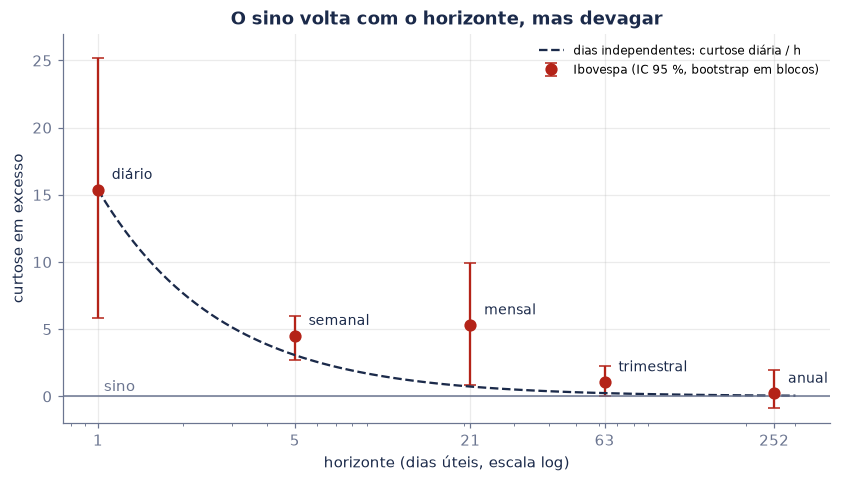

In [17]:
lp = np.log(ib)
horiz = [("diário", None, 1, 63), ("semanal", "W-FRI", 5, 13), ("mensal", "ME", 21, 6), ("trimestral", "QE", 63, 4), ("anual", "YE", 252, 3)]
linhas, curtoses = [], {}
for nome, regra_, h, L in horiz:
    if regra_ is None:
        x = r
    else:
        x = lp.resample(regra_).last().diff().dropna()
        x = x[(x.index >= "1995-01-01") & (x.index <= ("2025-12-31" if regra_ == "YE" else "2026-09-30"))]
    bc = mbb(x.values, curt, L=L, B=1000)
    curtoses[nome] = (h, curt(x.values), *ic(bc))
    linhas.append({"horizonte": nome, "nº de períodos": len(x), "desvio-padrão": float(x.std()), "dp diário × √h (7)": sd_d * math.sqrt(h), "assimetria": assim(x.values),
                   "curtose em excesso": curt(x.values), "IC 95 % (blocos)": f"{br(ic(bc)[0], 1)} a {br(ic(bc)[1], 1)}", "se os dias fossem independentes": curt(r.values) / h})
display(pd.DataFrame(linhas).style.format({"desvio-padrão": "{:.1%}", "dp diário × √h (7)": "{:.1%}", "assimetria": "{:+.2f}", "curtose em excesso": "{:.2f}", "se os dias fossem independentes": "{:.2f}"}, **fmt).hide(axis="index"))

fig, ax = plt.subplots()
hs = np.array([v[0] for v in curtoses.values()]); cs = np.array([v[1] for v in curtoses.values()])
lo_, hi_ = np.array([v[2] for v in curtoses.values()]), np.array([v[3] for v in curtoses.values()])
ax.errorbar(hs, cs, yerr=[cs - lo_, hi_ - cs], fmt="o", color=RED, ms=7, capsize=4, label="Ibovespa (IC 95 %, bootstrap em blocos)")
hh = np.logspace(0, np.log10(300), 100)
ax.plot(hh, curt(r.values) / hh, color=NAVY, ls="--", label="dias independentes: curtose diária / h")
ax.axhline(0, color=GREY, lw=1); ax.text(1.05, 0.4, "sino", color=GREY)
for (nome, v) in curtoses.items():
    ax.annotate(nome, (v[0], v[1]), (v[0] * 1.12, v[1] + 0.8), color=NAVY, fontsize=9)
ax.set_xscale("log"); ax.set(title="O sino volta com o horizonte, mas devagar", xlabel="horizonte (dias úteis, escala log)", ylabel="curtose em excesso", ylim=(-2, 27))
ax.set_xticks([1, 5, 21, 63, 252]); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(frameon=False, fontsize=8); plt.show()

**Leitura.** A curtose cai de 15,4 no diário para 0,2 no anual: com horizonte longo, **o sino volta**, o que é mais uma evidência contra as estáveis de Mandelbrot. Mas cai bem mais devagar que a conta dos dias independentes: a semanal fica em 4,5 (a conta dá 3,1), a mensal em 5,3 (a conta dá 0,7), a trimestral em 1,1 (0,2). Os dias ruins chegam juntos (volatilidade que muda, seção 8), e 1998 e 2008 tiveram meses inteiros de crise. A assimetria também muda de sinal: o dia tem assimetria positiva (+0,28, puxada pelo +33 % de 1999), o mês tem −1,13. **Quedas se acumulam; altas vêm em saltos.** O desvio-padrão segue $\sqrt{h}$ de perto (mensal 8,1 % contra 9,0 % pela raiz do tempo; anual 31,4 % contra 31,1 %).

## 11. Investidor: o dia de "1 em 370" e a regra dos 2 anos em 3

O vídeo diz que um movimento além de 3 desvios acontece uma vez a cada 370. Em dias úteis, isso é $252/370 = 0{,}68$ dia por ano: **um dia a cada ano e meio**. Para quem tem BOVA11, quantos aconteceram de verdade?

In [18]:
p3d = 2 * (1 - Phi(3))
alem3 = zi.abs() > 3
por_ano = alem3.groupby(zi.index.year).sum()
print(f"o sino espera {br(252 * p3d, 2)} dia por ano além de 3 dp (1 a cada {br(1 / p3d / 252, 2)} anos) -> {br(N * p3d, 1)} dias em {br(N / 252, 1)} anos")
print(f"aconteceram {int(alem3.sum())} ({br(alem3.sum() / (N * p3d), 1)} vezes mais); quedas além de −3 dp: {int((zi < -3).sum())} (o sino espera {br(N * p3d / 2, 1)})")
print(f"em {len(por_ano)} anos civis: {int((por_ano == 0).sum())} sem nenhum; os cinco piores: " + ", ".join(f"{a} ({v})" for a, v in por_ano.sort_values(ascending=False).head(5).items())
      + f" -> {int(por_ano.sort_values(ascending=False).head(5).sum())} dos {int(alem3.sum())} dias em cinco anos")
recente = zi.loc["2009":]
print(f"de 2009 a 2026, com o mesmo dp: {int((recente.abs() > 3).sum())} dias em {br(len(recente) / 252, 1)} anos (o sino espera {br(len(recente) * p3d, 1)})")
print(f"medindo com o dp do dia anterior (9): {int((ze_u.abs() > 3).sum())} dias além de 3 dp em {br(len(ze_u) / 252, 1)} anos (o sino espera {br(len(ze_u) * p3d, 1)})")

sig_hoje = float(np.sqrt(lam * var_e[-1] + (1 - lam) * xv[-1] ** 2))           # previsão (9) para o próximo pregão
sig_252 = float(r.iloc[-252:].std())
print(f"\nhoje (16/10/2026): dp do próximo dia pela (9) = {pct(sig_hoje, 2)}; pelos últimos 252 dias = {pct(sig_252, 2)}")
print(f"com R$ 100 mil em BOVA11, um dia de 3 dp é uma variação de {brl(3 * sig_252 * 1e5)} (dp de 252 dias) a {brl(3 * sig_hoje * 1e5)} (dp de hoje)")

o sino espera 0,68 dia por ano além de 3 dp (1 a cada 1,47 anos) -> 21,2 dias em 31,2 anos
aconteceram 113 (5,3 vezes mais); quedas além de −3 dp: 59 (o sino espera 10,6)
em 32 anos civis: 15 sem nenhum; os cinco piores: 1998 (23), 2008 (21), 1995 (19), 1997 (16), 2020 (11) -> 90 dos 113 dias em cinco anos
de 2009 a 2026, com o mesmo dp: 18 dias em 17,5 anos (o sino espera 11,9)
medindo com o dp do dia anterior (9): 59 dias além de 3 dp em 30,2 anos (o sino espera 20,6)

hoje (16/10/2026): dp do próximo dia pela (9) = 1,73 %; pelos últimos 252 dias = 1,20 %
com R$ 100 mil em BOVA11, um dia de 3 dp é uma variação de R$ 3.611 (dp de 252 dias) a R$ 5.184 (dp de hoje)


E a regra do ano? O vídeo diz que uma ação que oscila $\sigma$ ao ano termina dentro de $\pm\sigma$ em cerca de 2 anos a cada 3 e dentro de $\pm 2\sigma$ em 19 a cada 20. Com o Ibovespa: o desvio anual pela raiz do tempo (7) é o diário vezes $\sqrt{252}$, e os anos civis de 1995 a 2025 são o teste.

σ anual pela (7): 31,1 %; média dos anos (log): 11,6 %; desvio dos 31 anos: 31,4 %
anos civis dentro de ±1σ: 24 de 31 (77 %; sino 68 %) · dentro de ±2σ: 29 de 31 (94 %; sino 95 %)
janelas de 252 dias (sobrepostas): dentro de ±1σ 76 % · ±2σ 98 %
fora de ±2σ: 1999 (152 %), 2008 (−41 %)
com 31 anos, o erro-padrão de uma fração de 2/3 é 8 %


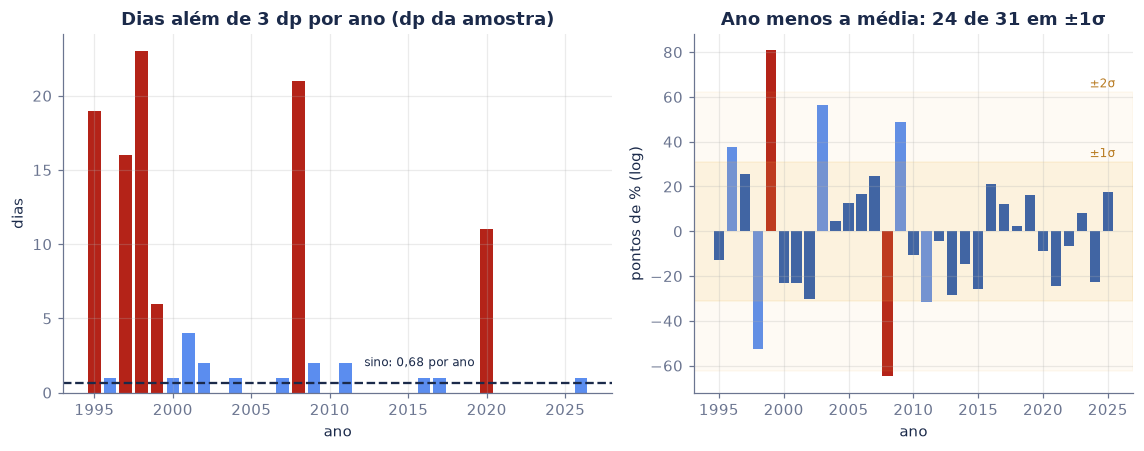

In [19]:
anos_ib = lp.resample("YE").last().diff().dropna()
anos_ib = anos_ib[(anos_ib.index.year >= 1995) & (anos_ib.index.year <= 2025)]
anos_ib.index = anos_ib.index.year
sig_a = sd_d * math.sqrt(252)
dev = anos_ib - anos_ib.mean()
d1, d2, na = int((dev.abs() <= sig_a).sum()), int((dev.abs() <= 2 * sig_a).sum()), len(anos_ib)
jan = r.cumsum().diff(252).dropna(); devj = jan - jan.mean()
print(f"σ anual pela (7): {pct(sig_a)}; média dos anos (log): {pct(anos_ib.mean())}; desvio dos {na} anos: {pct(anos_ib.std())}")
print(f"anos civis dentro de ±1σ: {d1} de {na} ({pct(d1 / na, 0)}; sino 68 %) · dentro de ±2σ: {d2} de {na} ({pct(d2 / na, 0)}; sino 95 %)")
print(f"janelas de 252 dias (sobrepostas): dentro de ±1σ {pct((devj.abs() <= sig_a).mean(), 0)} · ±2σ {pct((devj.abs() <= 2 * sig_a).mean(), 0)}")
print("fora de ±2σ: " + ", ".join(f"{a} ({pct(math.expm1(v), 0)})" for a, v in anos_ib[dev.abs() > 2 * sig_a].items()))
print(f"com {na} anos, o erro-padrão de uma fração de 2/3 é {pct(math.sqrt(2 / 3 * 1 / 3 / na), 0)}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
a1.bar(por_ano.index, por_ano.values, color=[RED if v >= 5 else LIGHT for v in por_ano.values])
a1.axhline(252 * p3d, color=NAVY, ls="--"); a1.text(2012.2, 252 * p3d + 1.1, f"sino: {br(252 * p3d, 2)} por ano", color=NAVY, fontsize=8)
a1.set(title="Dias além de 3 dp por ano (dp da amostra)", xlabel="ano", ylabel="dias")
a2.bar(anos_ib.index, 100 * dev, color=[RED if abs(v) > 2 * sig_a else (LIGHT if abs(v) > sig_a else BLUE) for v in dev])
for m_, a_ in ((1, 0.12), (2, 0.06)):
    a2.axhspan(-100 * m_ * sig_a, 100 * m_ * sig_a, color=AMBER, alpha=a_)
a2.text(2025.6, 100 * sig_a + 2, "±1σ", color=GOLD, fontsize=8, ha="right"); a2.text(2025.6, 200 * sig_a + 2, "±2σ", color=GOLD, fontsize=8, ha="right")
a2.set(title=f"Ano menos a média: {d1} de {na} em ±1σ", xlabel="ano", ylabel="pontos de % (log)")
plt.tight_layout(); plt.show()

**Leitura.** No dia a dia, o "1 em 370" do sino errou feio: em 31 anos, o Ibovespa teve 113 dias além de 3 desvios onde o sino previa 21, e eles vieram em bando (1998, 2008, 1995, 1997, 2020). Em 15 dos 32 anos não houve nenhum; em 1998, houve 23. Nas quedas o erro é maior: 59 contra 10,6. Medindo com a volatilidade do momento, o excesso cai, mas continua quase 3 vezes o previsto (59 contra 20,6). E um detalhe honesto: de 2009 para cá, com o desvio da amostra inteira (inflado pelos anos 90), foram 18 dias para 11,9 esperados, um excesso bem menor. **No ano, a regra funciona**: a raiz do tempo transforma 1,96 % ao dia em 31,1 % ao ano, e 24 dos 31 anos civis caíram dentro de ±1σ (77 %; o sino diz 68 %) e 29 dentro de ±2σ (94 %; o sino diz 95 %). Com só 31 anos, o erro-padrão de cada fração é de 8 pontos, então a diferença não é significativa. Para o investidor de longo prazo, o sino é um bom primeiro modelo. Para quem olha o dia, não.

## 12. Mesa de operações: VaR de 99 % em BOVA11 e o backtest — eqs. (11) e (12)

Uma mesa tem **R\$ 1 milhão em BOVA11**. Quanto ela pode perder num dia ruim? O **VaR de 99 % de um dia** é a perda que só deve ser ultrapassada em 1 dia a cada 100. Com desvio $\hat{\sigma}$ e um quantil $q$ da distribuição padronizada:

$$
\text{VaR}_{99\%} = V \cdot \hat{\sigma} \cdot q_{0{,}99}, \qquad q^{\text{sino}} = 2{,}326, \qquad q^{t}_\nu = t_\nu^{-1}(0{,}99)\,\sqrt{\frac{\nu-2}{\nu}} \tag{11}
$$

(a raiz faz a $t$ ter variância 1). Quatro jeitos, todos com informação só até a véspera: **sino** com o desvio dos últimos 252 dias; **$t$** com o mesmo desvio e $\nu$ estimado em 1995–2009, antes do teste; **histórico**, o pior 1 % dos últimos 252 dias; e **sino com o EWMA** (9). O backtest conta as **violações** (dias em que a perda passou do VaR) de 2010 a 16/10/2026 e aplica o teste de Kupiec (1995): com $x$ violações em $N$ dias e $p = 1\,\%$,

$$
LR = -2\ln\!\left[\frac{(1-p)^{N-x}\,p^{x}}{(1-\hat{p})^{N-x}\,\hat{p}^{x}}\right] \sim \chi^2_1, \qquad \hat{p} = \frac{x}{N} \tag{12}
$$

Antes: por que o fator de risco é o Ibovespa e não o preço do BOVA11? O ETF replica o índice, mas a série do BOVA11 no Yahoo tem ticks ruins.

In [20]:
bova = pd.read_csv("dados/bova11.csv", parse_dates=["data"]).set_index("data")["bova11"]
par = pd.concat([np.log(bova).diff(), np.log(ib).diff()], axis=1, keys=["BOVA11", "Ibovespa"], sort=True).dropna()
rec = par.loc["2019-01-01":]
print(f"2019–2026: correlação diária BOVA11 × Ibovespa = {br(rec.corr().iloc[0, 1], 4)}; dp da diferença = {pct(float((rec.BOVA11 - rec.Ibovespa).std()) * math.sqrt(252), 1)} ao ano (horários de fechamento diferentes)")
ruins = par[(par.BOVA11 - par.Ibovespa).abs() > 0.03].loc[:"2012-12-31"]
display(np.expm1(ruins).style.format("{:+.2%}", **fmt).format_index(lambda d: f"{d:%d/%m/%Y}")
        .set_caption("BOVA11 no Yahoo, 2009–2012: preço parado com o índice andando, e um +9 % devolvido sem o índice sair do lugar"))

2019–2026: correlação diária BOVA11 × Ibovespa = 0,9869; dp da diferença = 3,8 % ao ano (horários de fechamento diferentes)


,BOVA11,Ibovespa
data,,
20/01/2009,"+0,10%","-4,01%"
21/01/2009,"-0,36%","+3,41%"
18/06/2010,"+9,02%","-0,16%"
21/06/2010,"-7,99%","+0,61%"
02/09/2010,"+2,79%","-0,40%"
18/10/2011,"-2,35%","+2,08%"
25/10/2011,"+2,56%","-1,07%"
21/05/2012,"+0,00%","+3,81%"
22/05/2012,"+1,01%","-2,74%"


In [21]:
def kupiec(x, n_, p=0.01):                                 # (12): LR e p-valor (χ² com 1 g.l.: erfc(√(LR/2)))
    ph = x / n_
    lr = -2 * ((n_ - x) * math.log(1 - p) + x * math.log(p) - (n_ - x) * math.log(1 - ph) - x * math.log(ph))
    return lr, math.erfc(math.sqrt(lr / 2))

V = 1e6
R_ = np.expm1(r)                                           # retorno simples: P&L = V × R
nu_0 = ajusta_t(R_.loc[:"2009-12-31"].values)[2]           # ν estimado só com 1995–2009
q_n, q_t = float(Phi_inv(0.99)), t_inv(0.99, nu_0) * math.sqrt((nu_0 - 2) / nu_0)
v_ew = np.empty(N); v_ew[0] = R_.iloc[:21].var(); Rv = R_.to_numpy()
for t in range(1, N):
    v_ew[t] = lam * v_ew[t - 1] + (1 - lam) * Rv[t - 1] ** 2
sd252 = R_.rolling(252).std().shift(1)
var_df = pd.DataFrame({"R": R_, "sino, 252 dias": q_n * sd252, "t, 252 dias": q_t * sd252,
                       "histórico, 252 dias": -R_.rolling(252).quantile(0.01).shift(1), "sino, EWMA (9)": q_n * pd.Series(np.sqrt(v_ew), index=R_.index)})
bt = var_df.loc["2010-01-01":].dropna()
Nb = len(bt)
metodos = list(var_df.columns[1:])
print(f"ν estimado em 1995–2009: {br(nu_0, 2)} -> q da t com variância 1 = {br(q_t, 3)} (sino: {br(q_n, 3)})")
print(f"backtest: {mil(Nb)} pregões de {bt.index[0]:%d/%m/%Y} a {bt.index[-1]:%d/%m/%Y}; violações esperadas a 1 %: {br(0.01 * Nb, 1)}")

sd_hoje = float(R_.iloc[-252:].std())                       # informação até 16/10/2026, para o pregão de 19/10
amanha = {"sino, 252 dias": q_n * sd_hoje, "t, 252 dias": q_t * sd_hoje, "histórico, 252 dias": -float(R_.iloc[-252:].quantile(0.01)),
          "sino, EWMA (9)": q_n * math.sqrt(lam * v_ew[-1] + (1 - lam) * Rv[-1] ** 2)}
linhas = []
for c in metodos:
    viol = -bt.R > bt[c]
    xv_ = int(viol.sum()); lr, pv = kupiec(xv_, Nb)
    linhas.append({"método": c, "violações": xv_, "% dos dias": xv_ / Nb, "Kupiec p-valor (12)": pv, "VaR médio (R$)": V * bt[c].mean(),
                   "perda média na violação / VaR": float((-bt.R[viol] / bt[c][viol]).mean()), "anos com 5+ violações": int((viol.groupby(viol.index.year).sum() >= 5).sum()),
                   "VaR para 19/10/2026 (R$)": V * amanha[c]})
tab_var = pd.DataFrame(linhas)
display(tab_var.style.format({"% dos dias": "{:.2%}", "Kupiec p-valor (12)": "{:.3f}", "VaR médio (R$)": "{:,.0f}", "perda média na violação / VaR": "{:.2f}", "VaR para 19/10/2026 (R$)": "{:,.0f}"}, **fmt).hide(axis="index"))
pior = bt.R.idxmin()
print(f"pior dia do teste: {pior:%d/%m/%Y}, perda de {brl(-V * bt.R[pior])}; o VaR do sino era {brl(V * bt.loc[pior, 'sino, 252 dias'])} ({br(-bt.R[pior] / bt.loc[pior, 'sino, 252 dias'], 1)} vezes)")
print(f"no sino, a perda média na violação seria {br(float(phi(q_n)) / 0.01 / q_n, 2)} × VaR")

def t_es(alpha, nu):                                       # expected shortfall da t com variância 1, em desvios
    q = t_inv(alpha, nu); c = math.exp(math.lgamma((nu + 1) / 2) - math.lgamma(nu / 2)) / math.sqrt(nu * math.pi)
    return c * (1 + q * q / nu) ** (-(nu + 1) / 2) / (1 - alpha) * (nu + q * q) / (nu - 1) * math.sqrt((nu - 2) / nu)
es_n = float(phi(Phi_inv(0.975))) / 0.025
print(f"ES 97,5 %: sino {br(es_n, 3)} σ (VaR 99 % = {br(q_n, 3)} σ);  t com ν = {br(nu_0, 2)}: {br(t_es(0.975, nu_0), 3)} σ (VaR 99 % = {br(q_t, 3)} σ)")
viol_n = -bt.R > bt["sino, 252 dias"]
print(f"perda média nos {int(viol_n.sum())} dias de violação do sino: {brl(-V * bt.R[viol_n].mean())}, contra um VaR médio de {brl(V * bt['sino, 252 dias'][viol_n].mean())} nesses dias")

ν estimado em 1995–2009: 3,69 -> q da t com variância 1 = 2,658 (sino: 2,326)
backtest: 4.161 pregões de 04/01/2010 a 16/10/2026; violações esperadas a 1 %: 41,6


método,violações,% dos dias,Kupiec p-valor (12),VaR médio (R$),perda média na violação / VaR,anos com 5+ violações,VaR para 19/10/2026 (R$)
"sino, 252 dias",56,"1,35%","0,033",32.684,"1,49",4,28.161
"t, 252 dias",31,"0,75%","0,083",37.337,"1,60",1,32.171
"histórico, 252 dias",54,"1,30%","0,065",35.837,"1,44",6,25.943
"sino, EWMA (9)",65,"1,56%","0,001",30.883,"1,32",5,41.304


pior dia do teste: 12/03/2020, perda de R$ 147.797; o VaR do sino era R$ 38.060 (3,9 vezes)
no sino, a perda média na violação seria 1,15 × VaR
ES 97,5 %: sino 2,338 σ (VaR 99 % = 2,326 σ);  t com ν = 3,69: 2,857 σ (VaR 99 % = 2,658 σ)
perda média nos 56 dias de violação do sino: R$ 45.047, contra um VaR médio de R$ 29.892 nesses dias


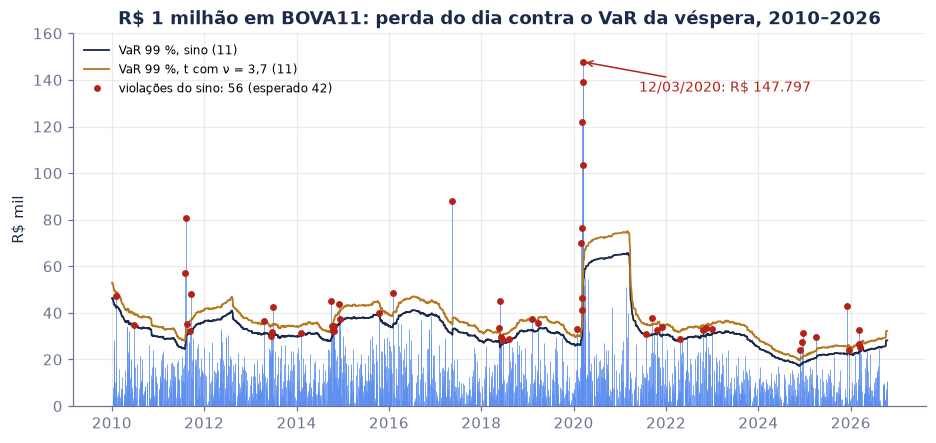

In [22]:
fig, ax = plt.subplots(figsize=(10, 4.4))
perda = -V * bt.R / 1e3
ax.vlines(bt.index, 0, perda.clip(lower=0), color=LIGHT, lw=0.5)
ax.plot(bt.index, V * bt["sino, 252 dias"] / 1e3, color=NAVY, lw=1.2, label="VaR 99 %, sino (11)")
ax.plot(bt.index, V * bt["t, 252 dias"] / 1e3, color=GOLD, lw=1.2, label=f"VaR 99 %, t com ν = {br(nu_0, 1)} (11)")
v_n = -bt.R > bt["sino, 252 dias"]
ax.plot(bt.index[v_n], perda[v_n], "o", color=RED, ms=3.5, label=f"violações do sino: {int(v_n.sum())} (esperado {br(0.01 * Nb, 0)})")
ax.annotate(f"12/03/2020: {brl(-V * bt.R[pior])}", (pior, -V * bt.R[pior] / 1e3), (pd.Timestamp("2021-06-01"), 135), color=RED, fontsize=9, arrowprops=dict(arrowstyle="->", color=RED))
ax.set(title="R$ 1 milhão em BOVA11: perda do dia contra o VaR da véspera, 2010–2026", ylabel="R$ mil", ylim=(0, 160)); ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.show()

**Leitura.** O VaR do sino estourou 56 vezes onde deveria estourar 42, e o teste de Kupiec o rejeita a 5 % (p-valor 0,033). O pior é o sino com EWMA (65 violações, p-valor 0,001): ele acompanha a volatilidade, mas o quantil 2,326 continua fino demais para a cauda que sobra (seção 8). A $t$, com $\nu = 3{,}7$ estimado antes do teste, erra para o outro lado: 31 violações, conservadora, com um VaR médio 14 % maior. O histórico fica no meio (54, p-valor 0,065). Nenhum dos quatro acerta o 1 %. E em todos, **quando o VaR estoura, estoura por bastante**: a perda média nos dias de violação é 1,3 a 1,6 vez o VaR, contra 1,15 no sino; em 12/03/2020, a perda foi 3,9 vezes o VaR do sino. É por isso que a regulação de mercado trocou o VaR de 99 % pelo *expected shortfall* de 97,5 %, a perda média além do quantil (nota técnica). Um detalhe da segunda-feira 19/10/2026: o EWMA dá o maior VaR (R\$ 41 mil) porque ainda carrega a alta de 7,7 % do dia 05/10. Para o desvio-padrão, susto para cima também é risco.

## 13. O que o sino não vê

1. **A volatilidade muda.** O sino tem um $\sigma$ só; o mercado alterna calma e crise, e os dias ruins chegam juntos (seção 8). Modelos de volatilidade condicional (ARCH de Engle, 1982; GARCH de Bollerslev, 1986) atacam isso; o EWMA (9) é o caso mais simples.
2. **Mesmo descontando isso, a cauda é gorda.** O expoente da cauda do Ibovespa fica perto de 3 (seção 9): eventos de 5 e 6 desvios acontecem, e a curtose de amostra não é um número confiável.
3. **Quedas e altas não são simétricas.** No mês, a assimetria é negativa: crises se acumulam em semanas ruins seguidas. O sino é simétrico.
4. **Os ativos caem juntos.** O sino de uma carteira supõe correlações estáveis; nas crises, elas sobem e a diversificação some quando mais se precisa dela.
5. **Saltos e liquidez.** Em 18/05/2017 e em março de 2020 houve *circuit breaker*: o preço pulou e não havia como sair no caminho. Nenhum desvio-padrão mede o preço que você não consegue negociar.

### Para praticar (respostas na célula seguinte)

1. Pelo sino, qual a chance de um resultado além de 2,5 desvios? Isso é 1 em quanto?
2. Uma ação oscila 2 % ao dia. Qual a oscilação anual pela eq. (7)? Entre quais retornos ela fica em 19 anos a cada 20?
3. Sem saber a distribuição, quanto, no mínimo, fica dentro de 4 desvios (Chebyshev)? E no sino?
4. Qual a curtose em excesso de uma $t$ com 5 graus de liberdade? E com 6? E com 4?
5. VaR de 99 % de um dia para R\$ 1 milhão com $\sigma$ = 1,5 % ao dia: pelo sino e por uma $t$ com 4 graus de liberdade ($t_4^{-1}(0{,}99) = 3{,}747$).

In [23]:
print("1)", f"P(|Z| > 2,5) = {pct(2 * (1 - Phi(2.5)), 2)} -> 1 em {br(1 / (2 * (1 - Phi(2.5))), 0)};  "
      f"Mills: entre {pct(2 * float(phi(2.5)) / 2.5 * (1 - 1 / 2.5 ** 2), 2)} e {pct(2 * float(phi(2.5)) / 2.5, 2)}")
print("2)", f"2 % × √252 = {pct(0.02 * math.sqrt(252))} ao ano; em 19 anos de 20, entre {pct(-2 * 0.02 * math.sqrt(252))} e +{pct(2 * 0.02 * math.sqrt(252))} (±2σ)")
print("3)", f"Chebyshev: pelo menos 1 − 1/16 = {pct(1 - 1 / 16, 2)}; sino: {pct(2 * Phi(4) - 1, 4)}")
print("4)", f"ν = 5: 6/(5−4) = 6;  ν = 6: 6/2 = 3;  ν = 4: infinita (o 4º momento não existe);  6/(ν−4) = 2 -> ν = {4 + 6 / 2:g} (MV no Ibovespa padronizado: {br(nu_e, 2)})")
q4 = t_inv(0.99, 4)
print("5)", f"sino: 1.000.000 × 1,5 % × 2,326 = {brl(1e6 * 0.015 * q_n)};  t com 4 g.l.: q = {br(q4, 3)} × √(2/4) = {br(q4 * math.sqrt(0.5), 3)} -> {brl(1e6 * 0.015 * q4 * math.sqrt(0.5))}")
assert round(q4, 3) == 3.747

1) P(|Z| > 2,5) = 1,24 % -> 1 em 81;  Mills: entre 1,18 % e 1,40 %
2) 2 % × √252 = 31,7 % ao ano; em 19 anos de 20, entre −63,5 % e +63,5 % (±2σ)
3) Chebyshev: pelo menos 1 − 1/16 = 93,75 %; sino: 99,9937 %
4) ν = 5: 6/(5−4) = 6;  ν = 6: 6/2 = 3;  ν = 4: infinita (o 4º momento não existe);  6/(ν−4) = 2 -> ν = 7 (MV no Ibovespa padronizado: 7,99)
5) sino: 1.000.000 × 1,5 % × 2,326 = R$ 34.895;  t com 4 g.l.: q = 3,747 × √(2/4) = 2,649 -> R$ 39.742


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Binomial | $P(K=k) = \binom{n}{k}/2^n$ | 924 de 4.096 caminhos; 613 bolinhas no meio (esperado 612,3) |
| (2) De Moivre–Laplace | $P(K=k) \approx e^{-(k-n/2)^2/(n/2)}/\sqrt{\pi n/2}$ | 2 % de erro no meio com 12 fileiras |
| (3) Raiz quadrada | $\operatorname{dp}(S_n) = \sqrt{n}$ | 19,92 ≈ 20 em 400 passos |
| (4) Teorema central do limite | $(S_n - n\mu)/(\sigma\sqrt{n}) \to N(0,1)$ | 100 uniformes; curtose −1,2/n |
| (5) Sino | $P(\lvert Z\rvert \le k) = \operatorname{erf}(k/\sqrt{2})$ | 68,27 · 95,45 · 99,73 %; 1 em 370 |
| (6) Chebyshev | $P(\lvert X-\mu\rvert \ge k\sigma) \le 1/k^2$ | ≥ 75 % em 2 dp, para qualquer distribuição |
| (7) Raiz do tempo | $\sigma_T = \sigma_1\sqrt{T}$ | 1 % ao dia = 15,9 % ao ano |
| (8) $t$ de Student | variância $\nu/(\nu-2)$, curtose $6/(\nu-4)$ | 78 dias além de 4 dp em 40 anos simulados |
| (9) EWMA | $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)r_{t-1}^2$ | curtose do Ibovespa de 15 para ~2 |
| (10) Hill | $\hat{\alpha}_k = [\frac{1}{k}\sum \ln(X_{(i)}/X_{(k+1)})]^{-1}$ | cauda do Ibovespa com expoente ≈ 3 |
| (11) VaR | $V\,\hat{\sigma}\,q_{0{,}99}$ | R\$ 1 milhão em BOVA11 |
| (12) Kupiec | $LR \sim \chi^2_1$ | o sino rejeitado no backtest de 2010–2026 |

### Referências

- Fama, E. F. (1965). The behavior of stock-market prices. *Journal of Business*, 38(1), 34–105.
- Mandelbrot, B. (1963). The variation of certain speculative prices. *Journal of Business*, 36(4), 394–419.
- Hill, B. M. (1975). A simple general approach to inference about the tail of a distribution. *Annals of Statistics*, 3(5), 1163–1174.
- Gopikrishnan, P.; Plerou, V.; Amaral, L. A. N.; Meyer, M.; Stanley, H. E. (1999). Scaling of the distribution of fluctuations of financial market indices. *Physical Review E*, 60(5), 5305–5316.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- J.P. Morgan/Reuters (1996). *RiskMetrics — Technical Document*, 4ª ed.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, 17(3), 1217–1241.
- Dados: Ibovespa (^BVSP) e BOVA11 (BOVA11.SA), fechamentos diários do Yahoo Finance até 16/10/2026.

*Gabriel Pires · gabrielppires.com · O vídeo é inspirado em* Quant Finance from Scratch*, de @quantfinancetogo. Simulação nas seções 0–6; dados reais do Ibovespa e do BOVA11 nas seções 7–12. Só educação, não é recomendação de investimento.*